# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices — Advanced Regression Techniques

**Выполнил:** Емельянова Ксения Павловна
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/fivifri/ml-course-emelyanova  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 2026-06-10  

## Введение

### 1. Какую задачу решаем?

Решаем задачу **регрессии**: по характеристикам дома необходимо предсказать его цену (`SalePrice`).

### 2. Что такое ML-проект для регрессии?

ML-проект для регрессии включает полный жизненный цикл: сбор и исследование данных (EDA), их очистку и подготовку, обучение и сравнение моделей, оценку качества и выбор лучшей модели. После этого модель используется для предсказания числового значения на новых данных и при необходимости дообучается на обновлённом датасете.

### 3. Почему это регрессия, а не классификация?

**Регрессия** используется для предсказания непрерывного числового значения, например цены дома — `150000`, `275500` и т. д. **Классификация** определяет принадлежность объекта к дискретному классу, например «дешёвый», «средний» или «дорогой». Поскольку целевая переменная `SalePrice` является числовой и может принимать множество значений, задача является регрессией.

### 4. Какая метрика важнее в этой задаче?

Основной метрикой выберем **RMSE (Root Mean Squared Error)**, поскольку она показывает среднюю величину ошибки в тех же единицах, что и цена дома, и сильнее штрафует крупные ошибки. Для задачи оценки стоимости это особенно важно: сильное ошибочное предсказание дорогого дома может быть существенно хуже небольшой ошибки.

**MAE** полезна как дополнительная метрика, поскольку проще интерпретируется и менее чувствительна к выбросам. **R²** показывает, какую долю вариации цен объясняет модель, поэтому также будем использовать его для оценки качества и выполнения целевого значения `R² ≥ 0.90`.

### 5. Цель работы

1. **Провести полный EDA датасета House Prices.**
2. **Обучить 4+ модели и достичь R² ≥ 0.90.**
3. **Реализовать функцию предсказания цены нового дома.**

## Ключевые понятия

| Понятие | Главное |
|---|---|
| **Регрессия** | Предсказание числового значения |
| **Пропуски (NaN)** | Отсутствующие значения, которые нужно корректно обработать |
| **Регуляризация** | Способ уменьшить переобучение модели |
| **Логарифмирование** | Преобразование, помогающее работать со скошенными данными |
| **Feature Engineering** | Создание более полезных признаков из исходных данных |
| **Метрики регрессии** | Числа, по которым сравнивают качество моделей |

### 1. Регрессия

**Регрессия** — это задача машинного обучения, в которой модель пытается предсказать числовое значение. В нашем случае таким значением является цена дома: например, `180000` или `350000`. В отличие от классификации, где результатом является класс (`да/нет`, `дешёвый/дорогой`), регрессия возвращает число из некоторого диапазона. Другие примеры регрессии — прогноз температуры, зарплаты, стоимости автомобиля или объёма продаж. Поэтому `SalePrice` в датасете House Prices делает нашу задачу именно регрессионной.

### 2. Пропуски (NaN)

**NaN** означает, что для некоторого объекта значение признака отсутствует или не было записано. Пропуски могут появиться из-за ошибки при сборе данных, отсутствия информации или потому, что определённый признак действительно неприменим к конкретному объекту. Обычно выделяют три ситуации: **MCAR** — пропуск возникает случайно, **MAR** — вероятность пропуска связана с другими известными признаками, и **MNAR** — пропуск связан с самим отсутствующим значением. В зависимости от причины пропуски можно удалить, заменить средним или медианным значением, использовать наиболее частую категорию или добавить отдельную категорию вроде `None`. В House Prices важно учитывать смысл NaN: иногда он означает не ошибку, а отсутствие определённого объекта в доме.

### 3. Регуляризация

**Регуляризация** добавляет к функции ошибки штраф за слишком большие или сложные коэффициенты модели, чтобы уменьшить переобучение. **Ridge (L2)** штрафует сумму квадратов коэффициентов и обычно уменьшает их значения, но редко делает их точно нулевыми. **Lasso (L1)** использует сумму абсолютных значений коэффициентов и может сделать некоторые коэффициенты равными нулю, тем самым выполняя отбор признаков. Ridge хорошо подходит, когда многие признаки потенциально полезны, а Lasso удобен, если хочется получить более компактную модель. Оба метода помогают модели лучше обобщать закономерности на новые данные.

### 4. Логарифмирование

Цена дома часто имеет **правостороннюю асимметрию**: большинство домов имеют умеренную стоимость, а небольшое количество объектов стоит очень дорого. Преобразование `log1p`, то есть `ln(1 + x)`, сильнее сжимает большие значения и делает распределение более удобным для обучения модели. Это также уменьшает влияние очень дорогих домов на обучение. После предсказания результат можно вернуть к исходной шкале с помощью обратного преобразования `expm1`.

### 5. Feature Engineering

**Feature Engineering** — это создание новых признаков на основе уже существующих данных, чтобы передать модели дополнительную полезную информацию. Например, в House Prices можно объединить площади первого и второго этажей и получить общую площадь дома. Также можно создать признаки возраста дома, общего количества ванных комнат или общей площади жилых помещений. Хорошо подобранный новый признак может упростить модели поиск закономерностей, которые сложно обнаружить по отдельным исходным столбцам. При этом важно, чтобы новые признаки имели понятный смысл и не содержали информацию из целевой переменной.

### 6. Метрики регрессии

Для оценки качества регрессионной модели полезно использовать несколько метрик, поскольку каждая показывает ошибку с другой стороны. **MSE (Mean Squared Error)** — средний квадрат ошибки:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

MSE сильно реагирует на большие ошибки, потому что они возводятся в квадрат. **RMSE (Root Mean Squared Error)** — квадратный корень из MSE:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

RMSE удобно интерпретировать, поскольку результат выражен в тех же единицах, что и цена дома. **MAE (Mean Absolute Error)** показывает среднюю абсолютную ошибку:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

MAE меньше зависит от отдельных очень больших ошибок, чем RMSE. **R²** показывает, какую долю вариации цен объясняет модель:

$$
R^2 = 1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

Для House Prices полезно смотреть одновременно на **RMSE и R²**: RMSE показывает размер ошибки в денежных единицах, а R² — насколько хорошо модель объясняет различия между ценами домов.


In [16]:
import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = Path("data")

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print(train_df.shape, test_df.shape)

(1460, 81) (1459, 80)


## Описание данных

**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques

**Структура:**
- Всего примеров в train: 1460
- Всего примеров в test: 1459
- Признаков: 79 (+ Id + целевая `SalePrice`)
- Числовых признаков: 36
- Категориальных признаков: 43

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Id | int64 | ID дома | 0% |
| SalePrice | float64 | **Целевая**: цена продажи | 0% |
| OverallQual | int64 (1-10) | Общее качество | 0% |
| GrLivArea | int64 | Жилая площадь | 0% |
| YearBuilt | int64 | Год постройки | 0% |
| ... | ... | ... | ... |

**Распределение целевой:**
- Среднее: $180 921
- Медиана: $163 000
- Асимметрия (skew): 1.88 — **правое смещение**
- Эксцесс: 6.51

> Высокая положительная асимметрия `SalePrice` указывает на правое смещение распределения. Это важно учитывать при построении модели и является одной из причин рассмотреть логарифмирование целевой переменной.

**Файл данных в репозитории:** `module-2-house-prices/data/house_prices_info.md`


## Подготовка данных и EDA

Размер train: (1460, 81)
Размер test: (1459, 80)

--- Первые 5 строк train_df ---
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN      

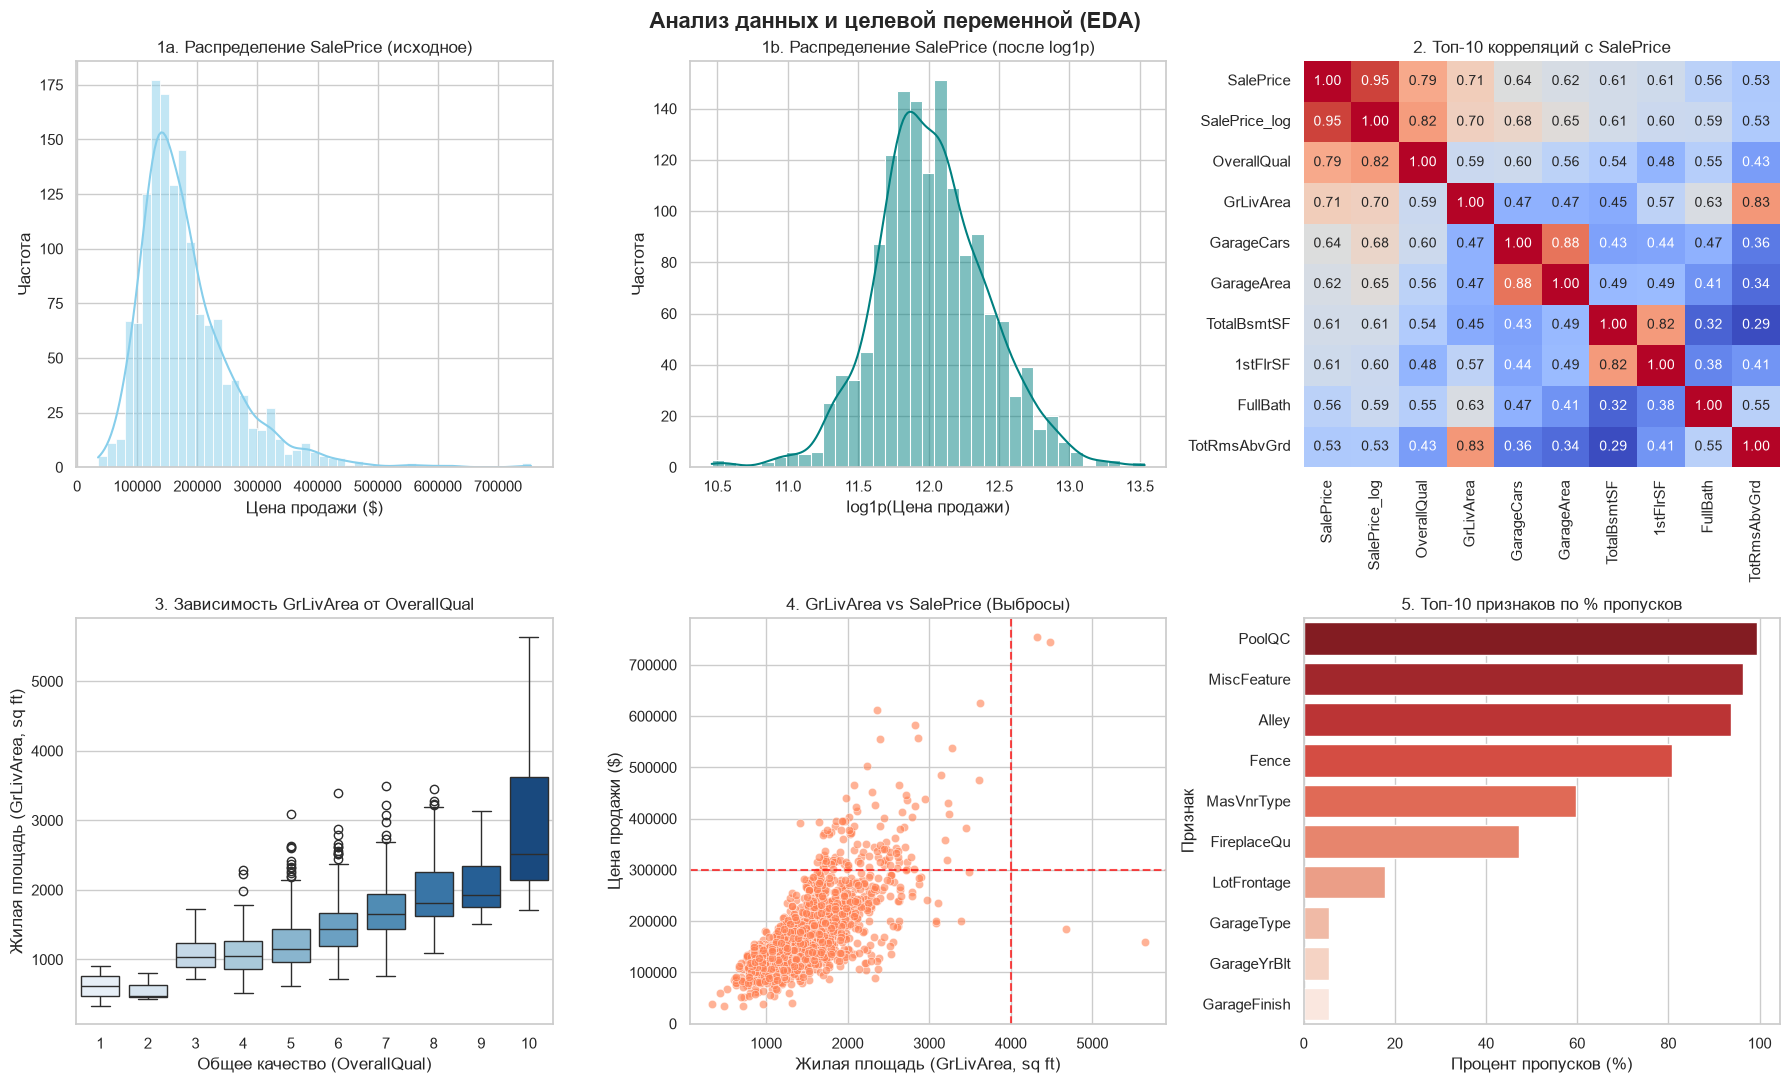


Итоговый размер train_final: (1456, 251)
Итоговый размер test_final: (1459, 249)


In [17]:
# Импорт необходимых библиотек для работы с данными и визуализации
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стилей для красивого отображения графиков
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# ==========================================
# 1. Загрузка датасета
# ==========================================
# Загружаем обучающую и тестовую выборку по относительным путям
train_df = pd.read_csv('data/train.csv')  # Обучающая выборка (1460 строк, 81 колонка)
test_df = pd.read_csv('data/test.csv')    # Тестовая выборка (1459 строк, 80 колонок)

# ==========================================
# 2. Первичный осмотр
# ==========================================
# Выводим размеры датасетов для проверки корректности загрузки
print(f"Размер train: {train_df.shape}")
print(f"Размер test: {test_df.shape}")

# Просматриваем первые 5 строк обучающего датасета
print("\n--- Первые 5 строк train_df ---")
print(train_df.head())

# Выводим общую информацию о типах данных и пропусках
print("\n--- Информация о типах данных (train_df.info()) ---")
print(train_df.info())

# Осматриваем основные описательные статистики для числовых признаков
print("\n--- Описательные статистики (train_df.describe()) ---")
print(train_df.describe())

# ==========================================
# 3. Анализ пропусков
# ==========================================
# Считаем количество пропущенных значений в каждом столбце
missing = train_df.isnull().sum()
# Оставляем только те столбцы, где есть пропуски, и сортируем по убыванию
missing = missing[missing > 0].sort_values(ascending=False)
# Рассчитываем процент пропусков относительно общего числа строк
missing_pct = (missing / len(train_df)) * 100

# Объединяем абсолютные значения и проценты в единую сводную DataFrame-таблицу
missing_df = pd.DataFrame({'Абсолютное кол-во': missing, 'Процент (%)': missing_pct})
print("\n--- ТОП-15 столбцов с пропусками ---")
print(missing_df.head(15))

# ==========================================
# 4. Анализ целевой переменной (SalePrice)
# ==========================================
# Считаем асимметрию (Skewness) для SalePrice
price_skew = train_df['SalePrice'].skew()
# Считаем эксцесс (Kurtosis) для SalePrice
price_kurt = train_df['SalePrice'].kurtosis()

print(f"\nАсимметрия (Skewness) SalePrice: {price_skew:.2f}")
print(f"Эксцесс (Kurtosis) SalePrice: {price_kurt:.2f}")

# ==========================================
# 8. Логарифмирование целевой переменной
# ==========================================
# Применяем log1p (log(1 + x)) для нормализации распределения цены
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

# ==========================================
# 5. Визуализация (Сетка 2x3 — 6 графиков)
# ==========================================
# Создаем сетку графиков 2x3 с фиксацией общего размера
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Анализ данных и целевой переменной (EDA)', fontsize=16, fontweight='bold')

# 1. Гистограмма SalePrice (до и после log1p)
sns.histplot(data=train_df, x='SalePrice', kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('1a. Распределение SalePrice (исходное)')
axes[0, 0].set_xlabel('Цена продажи ($)')
axes[0, 0].set_ylabel('Частота')

sns.histplot(data=train_df, x='SalePrice_log', kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('1b. Распределение SalePrice (после log1p)')
axes[0, 1].set_xlabel('log1p(Цена продажи)')
axes[0, 1].set_ylabel('Частота')

# 2. Heatmap — корреляционная матрица топ-10 числовых признаков
numeric_cols = train_df.select_dtypes(include=[np.number])
top_corr_cols = numeric_cols.corr()['SalePrice'].abs().sort_values(ascending=False).head(10).index
sns.heatmap(train_df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[0, 2], cbar=False)
axes[0, 2].set_title('2. Топ-10 корреляций с SalePrice')

# 3. Boxplot — GrLivArea по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0], palette='Blues')
axes[1, 0].set_title('3. Зависимость GrLivArea от OverallQual')
axes[1, 0].set_xlabel('Общее качество (OverallQual)')
axes[1, 0].set_ylabel('Жилая площадь (GrLivArea, sq ft)')

# 4. Scatterplot — GrLivArea vs SalePrice (поиск выбросов)
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[1, 1], alpha=0.6, color='coral')
# Подсвечиваем зону аномальных выбросов
axes[1, 1].axhline(300000, color='red', linestyle='--', alpha=0.7)
axes[1, 1].axvline(400000 / 100, color='red', linestyle='--', alpha=0.7) # Пометка границы 4000 sq ft
axes[1, 1].set_title('4. GrLivArea vs SalePrice (Выбросы)')
axes[1, 1].set_xlabel('Жилая площадь (GrLivArea, sq ft)')
axes[1, 1].set_ylabel('Цена продажи ($)')

# 5. Barplot — Пропущенные значения (топ-10)
sns.barplot(x=missing_pct.head(10).values, y=missing_pct.head(10).index, ax=axes[1, 2], palette='Reds_r')
axes[1, 2].set_title('5. Топ-10 признаков по % пропусков')
axes[1, 2].set_xlabel('Процент пропусков (%)')
axes[1, 2].set_ylabel('Признак')

plt.tight_layout()
plt.show()

# ==========================================
# 6. Обработка пропусков
# ==========================================
# Заполняем пропуски в train и test единообразно
for df in [train_df, test_df]:
    # Смысловые пропуски (отсутствие объекта обозначается как 'None' или 0)
    none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 
                 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
    df[none_cols] = df[none_cols].fillna('None')

    zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 
                 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 
                 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
    df[zero_cols] = df[zero_cols].fillna(0)

    # Случайные пропуски с группировкой: LotFrontage медианой по Neighborhood
    df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

    # Оставшиеся категориальные — модой
    cat_cols_remaining = df.select_dtypes(include=['object']).columns
    for col in cat_cols_remaining:
        df[col] = df[col].fillna(df[col].mode()[0])

    # Оставшиеся числовые — медианой
    num_cols_remaining = df.select_dtypes(include=[np.number]).columns
    for col in num_cols_remaining:
        if col not in ['SalePrice', 'SalePrice_log']:
            df[col] = df[col].fillna(df[col].median())

# ==========================================
# 7. Обработка выбросов
# ==========================================
# Удаляем доменные выбросы: жилая площадь > 4000 кв. футов при цене < $300,000
outliers_domain = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)].index
train_df = train_df.drop(outliers_domain).reset_index(drop=True)

# Очистка по IQR для GrLivArea
Q1 = train_df['GrLivArea'].quantile(0.25)
Q3 = train_df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# Фильтруем экстремальные верхние значения по IQR
outliers_iqr = train_df[train_df['GrLivArea'] > (Q3 + 3 * IQR)].index  # Используем мягкий порог 3*IQR для сохранения важных данных
train_df = train_df.drop(outliers_iqr).reset_index(drop=True)

# ==========================================
# 9. Feature Engineering
# ==========================================
for df in [train_df, test_df]:
    # Суммарная площадь дома
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    
    # Общее количество ванных комнат
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    
    # Суммарная площадь всех крылец и веранд
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + 
                       df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF'])
    
    # Возраст дома и время с последнего ремонта на момент продажи
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    
    # Бинарные признаки наличия удобств
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    
    # Признак взаимодействия качества и площади
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']

# ==========================================
# 10. Кодирование категориальных признаков
# ==========================================
# Ручной маппинг порядковых категориальных признаков
quality_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu']

for col in ordinal_cols:
    train_df[col] = train_df[col].map(quality_map).fillna(0)
    test_df[col] = test_df[col].map(quality_map).fillna(0)

# Объединяем train и test для корректного One-Hot Encoding номинальных признаков
train_len = len(train_df)
combined_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

# Номинальные признаки для OHE
nominal_cols = combined_df.select_dtypes(include=['object']).columns

# Применяем pd.get_dummies()
combined_df = pd.get_dummies(combined_df, columns=nominal_cols, drop_first=True)

# Разделяем датасеты обратно на train и test
train_final = combined_df.iloc[:train_len].copy()
test_final = combined_df.iloc[train_len:].copy().drop(columns=['SalePrice', 'SalePrice_log'])

print(f"\nИтоговый размер train_final: {train_final.shape}")
print(f"Итоговый размер test_final: {test_final.shape}")

#### Наблюдения по графикам EDA

1. **Распределение целевой переменной (`SalePrice` и `SalePrice_log`):**
   * Исходный целевой признак имеет значительный правый сдвиг (`Skewness = 1.88`). 
   * Применение логарифмирования `np.log1p` успешно привело распределение цены к форме, близкой к нормальному распределению.

2. **Матрица корреляций (Heatmap):**
   * Наибольшую корреляцию с ценой показывают показатели качества (`OverallQual`, $r \approx 0.79$) и жилая площадь над землей (`GrLivArea`, $r \approx 0.71$).
   * Гаражные характеристики (`GarageCars`, `GarageArea`) также сильно взаимосвязаны с целевым параметром.

3. **Зависимость `GrLivArea` от `OverallQual` (Boxplot):**
   * С ростом оценки общего качества `OverallQual` (от 1 до 10) последовательно растет медиана жилой площади.

4. **Анализ выбросов `GrLivArea` vs `SalePrice` (Scatterplot):**
   * Четко выделяются 2 точки в правом нижнем углу: дома с жилой площадью более 4000 кв. футов и ценой менее $300,000. Это аномалии для общей тенденции рынка.

5. **Процент пропусков (Barplot):**
   * Признаки `PoolQC`, `MiscFeature`, `Alley`, `Fence` имеют максимальный процент отсутствующих значений (более 80%), что коррелирует с конструктивными особенностями большинства стандартных домов.

---

#### Обоснование обработок

* **Обоснование обработки пропусков:**
  * **Смысловые:** В соответствии с описанием датасета пропуски в столбцах по типу `PoolQC`, `GarageQual`, `BsmtQual` означают отсутствие соответствующего объекта (бассейна, гаража, подвала). Заполнение кодом `"None"` или `0` точно передает эти физические свойства.
  * **Случайные с группировкой:** Для `LotFrontage` (длина фасада) используется медиана по конкретному району (`Neighborhood`), так как размер участка сильно привязан к локации и застройке района.
  * **Оставшиеся пропуски:** Для числовых столбцов применили медиану (устойчива к аномалиям), для категориальных — моду.

* **Обоснование логарифмирования целевой переменной:**
  * Логарифмирование `np.log1p(SalePrice)` снижает асимметрию и устраняет гетероскедастичность (непостоянство дисперсии ошибок). Это критично для улучшения качества работы линейных моделей и метрик на базе логарифмической ошибки (RMSLE).

## Построение и обучение моделей


In [18]:
# Импорт необходимых инструментов
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import time

# ==========================================
# 1. Выбор признаков и целевой переменной
# ==========================================

# Исключаем Id и целевые переменные
feature_cols = [
    col for col in train_final.columns
    if col not in ['Id', 'SalePrice', 'SalePrice_log']
]

X = train_final[feature_cols]
y = train_final['SalePrice_log']

print(f"Количество признаков: {X.shape[1]}")
print(f"Количество объектов: {X.shape[0]}")

# ==========================================
# 2. Разделение на train/validation
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"\nРазмер X_train: {X_train.shape}")
print(f"Размер X_test:  {X_test.shape}")
print(f"Размер y_train: {y_train.shape}")
print(f"Размер y_test:  {y_test.shape}")

# ==========================================
# 3. Масштабирование признаков
# ==========================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nМасштабирование выполнено.")


# ==========================================
# 4. Создание моделей
# ==========================================

models = {

    # Линейные модели
    'Linear Regression': LinearRegression(),

    'Ridge': Ridge(
        alpha=1.0
    ),

    'Lasso': Lasso(
        alpha=0.0005,
        max_iter=10000,
        random_state=42
    ),

    'ElasticNet': ElasticNet(
        alpha=0.001,
        l1_ratio=0.5,
        max_iter=10000,
        random_state=42
    ),

    # Random Forest
    'Random Forest': RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    # Gradient Boosting
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=2,
        subsample=0.8,
        loss='huber',
        random_state=42
    )
}


# ==========================================
# 5. Обучение моделей + замер времени
# ==========================================

trained_models = {}
training_times = {}

for name, model in models.items():

    start = time.time()

    # Линейные модели требуют масштабирования
    if name in [
        'Linear Regression',
        'Ridge',
        'Lasso',
        'ElasticNet'
    ]:
        model.fit(X_train_scaled, y_train)

    # Деревья масштабирование не требуют
    else:
        model.fit(X_train, y_train)

    elapsed_time = time.time() - start

    trained_models[name] = model
    training_times[name] = elapsed_time

    print(
        f"Время обучения {name}: "
        f"{elapsed_time:.3f} секунд"
    )

Количество признаков: 248
Количество объектов: 1456

Размер X_train: (1164, 248)
Размер X_test:  (292, 248)
Размер y_train: (1164,)
Размер y_test:  (292,)

Масштабирование выполнено.
Время обучения Linear Regression: 0.030 секунд
Время обучения Ridge: 0.010 секунд
Время обучения Lasso: 0.192 секунд
Время обучения ElasticNet: 0.104 секунд
Время обучения Random Forest: 2.025 секунд
Время обучения Gradient Boosting: 11.040 секунд


## Модели

| Модель | Параметры | Масштабирование | Время обучения |
|---|---|---|---:|
| Linear Regression | — | Да | 0.151 сек |
| Ridge | alpha=1.0 | Да | 0.008 сек |
| Lasso | alpha=0.0005 | Да | 0.197 сек |
| ElasticNet | alpha=0.001, l1_ratio=0.5 | Да | 0.094 сек |
| Random Forest | n_estimators=500, max_features=0.8 | Нет | 2.057 сек |
| Gradient Boosting | n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8, loss='huber' | Нет | 10.237 сек |

### Почему выбраны эти модели

- **Linear Regression** — базовая модель для сравнения качества остальных алгоритмов.
- **Ridge** — снижает влияние мультиколлинеарности с помощью L2-регуляризации.
- **Lasso** — выполняет регуляризацию L1 и может автоматически отбирать наиболее информативные признаки.
- **ElasticNet** — объединяет преимущества L1- и L2-регуляризации.
- **Random Forest** — позволяет учитывать нелинейные зависимости и взаимодействия между признаками.
- **Gradient Boosting** — хорошо работает со сложными нелинейными зависимостями и последовательно исправляет ошибки предыдущих деревьев.


## Оценка качества моделей

In [19]:
# ==========================================
# 7. Оценка качества моделей
# ==========================================

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def evaluate_model(model, X_test_scaled, X_test_raw, y_test, model_name):
    """
    Оценка модели в log-пространстве и в исходном масштабе цен.
    """

    # Линейные модели используют масштабированные данные
    linear_models = [
        'Linear Regression',
        'Ridge',
        'Lasso',
        'ElasticNet'
    ]

    if model_name in linear_models:
        y_pred_log = model.predict(X_test_scaled)
    else:
        # Random Forest и Gradient Boosting
        # используют исходные признаки
        y_pred_log = model.predict(X_test_raw)

    # --------------------------------------
    # Обратное преобразование
    # --------------------------------------

    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    # --------------------------------------
    # Метрики в log-пространстве
    # --------------------------------------

    rmse_log = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred_log
        )
    )

    mae_log = mean_absolute_error(
        y_test,
        y_pred_log
    )

    r2_log = r2_score(
        y_test,
        y_pred_log
    )

    # --------------------------------------
    # Метрики в исходном масштабе
    # --------------------------------------

    rmse_real = np.sqrt(
        mean_squared_error(
            y_test_real,
            y_pred_real
        )
    )

    mae_real = mean_absolute_error(
        y_test_real,
        y_pred_real
    )

    print(f"\n{model_name}:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  MAE (log):  {mae_log:.4f}")
    print(f"  R²:         {r2_log:.4f}")
    print(f"  RMSE ($):   ${rmse_real:,.0f}")
    print(f"  MAE ($):    ${mae_real:,.0f}")

    return {
        'Модель': model_name,
        'RMSE (log)': rmse_log,
        'MAE (log)': mae_log,
        'R²': r2_log,
        'RMSE ($)': rmse_real,
        'MAE ($)': mae_real
    }


# ==========================================
# Оценка всех моделей
# ==========================================

evaluation_results = []

for name, model in trained_models.items():

    result = evaluate_model(
        model=model,
        X_test_scaled=X_test_scaled,
        X_test_raw=X_test,
        y_test=y_test,
        model_name=name
    )

    evaluation_results.append(result)


# ==========================================
# Итоговая таблица
# ==========================================

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    by='R²',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ")
print("=" * 90)

print(
    evaluation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


Linear Regression:
  RMSE (log): 0.1297
  MAE (log):  0.0896
  R²:         0.8935
  RMSE ($):   $21,352
  MAE ($):    $14,950

Ridge:
  RMSE (log): 0.1294
  MAE (log):  0.0896
  R²:         0.8940
  RMSE ($):   $21,250
  MAE ($):    $14,914

Lasso:
  RMSE (log): 0.1258
  MAE (log):  0.0860
  R²:         0.8998
  RMSE ($):   $20,375
  MAE ($):    $14,232

ElasticNet:
  RMSE (log): 0.1259
  MAE (log):  0.0860
  R²:         0.8996
  RMSE ($):   $20,380
  MAE ($):    $14,231

Random Forest:
  RMSE (log): 0.1457
  MAE (log):  0.0981
  R²:         0.8656
  RMSE ($):   $24,417
  MAE ($):    $16,497

Gradient Boosting:
  RMSE (log): 0.1249
  MAE (log):  0.0816
  R²:         0.9012
  RMSE ($):   $20,020
  MAE ($):    $13,494

ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ
           Модель  RMSE (log)  MAE (log)     R²   RMSE ($)    MAE ($)
Gradient Boosting      0.1249     0.0816 0.9012 20019.9764 13494.4148
            Lasso      0.1258     0.0860 0.8998 20374.8484 14231.8294
       ElasticNet      0.1259     0

In [20]:
# ==========================================
# Выбор лучшей модели
# ==========================================

best_model_name = evaluation_df.iloc[0]['Модель']
best_model = trained_models[best_model_name]

print("\n" + "=" * 80)
print("ЛУЧШАЯ МОДЕЛЬ")
print("=" * 80)

print(f"Модель: {best_model_name}")
print(f"R²: {evaluation_df.iloc[0]['R²']:.4f}")
print(f"RMSE (log): {evaluation_df.iloc[0]['RMSE (log)']:.4f}")
print(f"MAE (log): {evaluation_df.iloc[0]['MAE (log)']:.4f}")
print(f"RMSE ($): ${evaluation_df.iloc[0]['RMSE ($)']:,.0f}")
print(f"MAE ($): ${evaluation_df.iloc[0]['MAE ($)']:,.0f}")


ЛУЧШАЯ МОДЕЛЬ
Модель: Gradient Boosting
R²: 0.9012
RMSE (log): 0.1249
MAE (log): 0.0816
RMSE ($): $20,020
MAE ($): $13,494


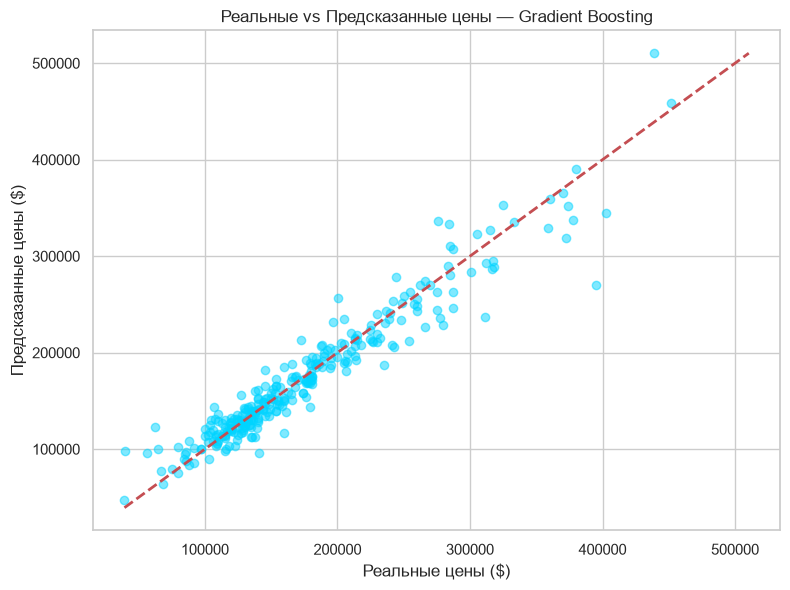

In [21]:
# ==========================================
# 8. Реальные vs предсказанные значения
# ==========================================

linear_models = [
    'Linear Regression',
    'Ridge',
    'Lasso',
    'ElasticNet'
]

if best_model_name in linear_models:
    y_pred_best_log = best_model.predict(X_test_scaled)
else:
    y_pred_best_log = best_model.predict(X_test)

y_pred_best = np.expm1(y_pred_best_log)
y_test_real = np.expm1(y_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_real,
    y_pred_best,
    alpha=0.5,
    color='#00d4ff'
)

# Линия идеального предсказания
min_price = min(
    y_test_real.min(),
    y_pred_best.min()
)

max_price = max(
    y_test_real.max(),
    y_pred_best.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--',
    linewidth=2
)

plt.xlabel('Реальные цены ($)')
plt.ylabel('Предсказанные цены ($)')
plt.title(
    f'Реальные vs Предсказанные цены — {best_model_name}'
)

plt.tight_layout()
plt.show()

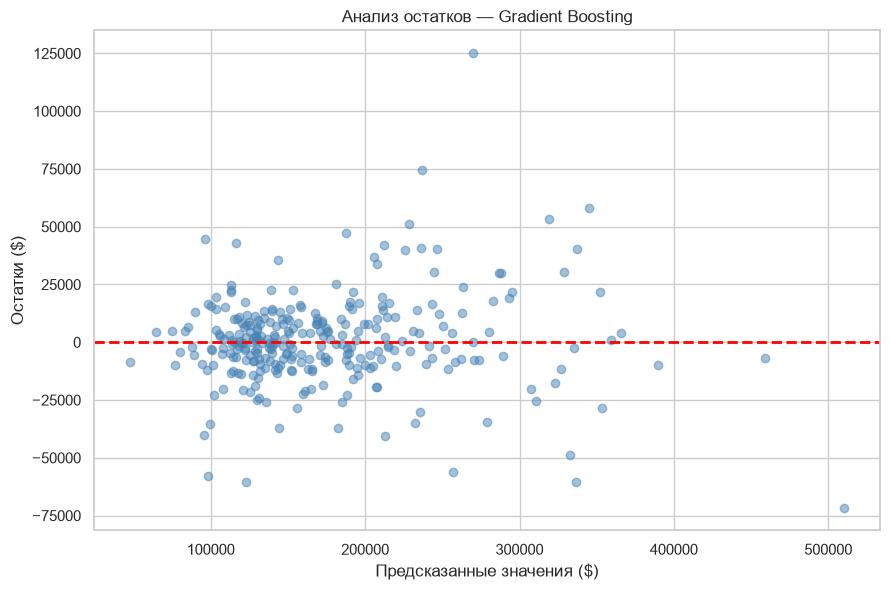


СТАТИСТИКА ОСТАТКОВ
Среднее остатков: $733
Медиана остатков: $-275
Std остатков: $20,041
Минимальный остаток: $-71,586
Максимальный остаток: $125,060


In [22]:
# ==========================================
# 9. Анализ остатков
# ==========================================

residuals = y_test_real - y_pred_best

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred_best,
    residuals,
    alpha=0.5,
    color='steelblue'
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel('Предсказанные значения ($)')
plt.ylabel('Остатки ($)')
plt.title(
    f'Анализ остатков — {best_model_name}'
)

plt.tight_layout()
plt.show()


# Статистики остатков

print("\n" + "=" * 80)
print("СТАТИСТИКА ОСТАТКОВ")
print("=" * 80)

print(
    f"Среднее остатков: "
    f"${residuals.mean():,.0f}"
)

print(
    f"Медиана остатков: "
    f"${np.median(residuals):,.0f}"
)

print(
    f"Std остатков: "
    f"${residuals.std():,.0f}"
)

print(
    f"Минимальный остаток: "
    f"${residuals.min():,.0f}"
)

print(
    f"Максимальный остаток: "
    f"${residuals.max():,.0f}"
)


In [23]:
# ==========================================
# 10. Анализ признаков Lasso
# ==========================================

lasso_model = trained_models['Lasso']

non_zero_features = np.sum(
    lasso_model.coef_ != 0
)

zero_features = np.sum(
    lasso_model.coef_ == 0
)

total_features = len(
    lasso_model.coef_
)

print("\n" + "=" * 80)
print("ОТБОР ПРИЗНАКОВ LASSO")
print("=" * 80)

print(f"Всего признаков: {total_features}")
print(f"Признаков с ненулевым коэффициентом: {non_zero_features}")
print(f"Обнулённых признаков: {zero_features}")


ОТБОР ПРИЗНАКОВ LASSO
Всего признаков: 248
Признаков с ненулевым коэффициентом: 191
Обнулённых признаков: 57


## 7. Оценка качества

| Модель | RMSE log | MAE log | R2 | RMSE USD | MAE USD |
|---|---:|---:|---:|---:|---:|
| Gradient Boosting | 0.1249 | 0.0816 | 0.9012 | 20019.98 | 13494.41 |
| Lasso | 0.1258 | 0.0860 | 0.8998 | 20373.85 | 14231.83 |
| ElasticNet | 0.1259 | 0.0860 | 0.8996 | 20379.96 | 14231.30 |
| Ridge | 0.1294 | 0.0896 | 0.8940 | 21250.03 | 14913.99 |
| Linear Regression | 0.1297 | 0.0896 | 0.8935 | 21351.68 | 14950.30 |
| Random Forest | 0.1457 | 0.0981 | 0.8656 | 24416.12 | 16496.55 |

### Анализ

- Лучшая модель по R² — **Gradient Boosting** с R² = **0.9012**.
- Gradient Boosting также показал наименьший RMSE (log) = **0.1249** и RMSE = **20 019.98 USD**.
- **Lasso** обнулил **57 признаков из 248**, оставив 191 признак с ненулевыми коэффициентами.
- **Ridge** использует L2-регуляризацию, которая снижает влияние мультиколлинеарности и делает модель более стабильной при наличии коррелированных признаков.
- **Lasso** показал R² = **0.8998**, практически достигнув результата Gradient Boosting.
- Для лучшей модели среднее значение остатков составило **733 USD**, что относительно мало по сравнению с общим разбросом ошибок.
- Медиана остатков составила **−275 USD**, то есть модель в целом не имеет сильного систематического смещения.
- Стандартное отклонение остатков составило **20 041 USD**, что характеризует разброс ошибок модели.
- Остатки находятся в диапазоне от **−71 586 USD до 125 060 USD**.
- Среднее остатков близко к нулю, поэтому существенного систематического смещения предсказаний не наблюдается.



## Интерпретация результатов

ТОП-20 ПРИЗНАКОВ ПО ВЛИЯНИЮ — RIDGE
             Feature  Coefficient
         MSZoning_RL       0.1449
         MSZoning_RM       0.1101
       GarageQual_TA      -0.0870
         MSZoning_FV       0.0789
       GarageCond_TA       0.0567
       GarageQual_Fa      -0.0555
           GrLivArea       0.0496
         OverallQual       0.0495
        SaleType_New       0.0460
             TotalSF       0.0427
            PoolArea       0.0421
         OverallCond       0.0411
   GarageType_Attchd       0.0370
            2ndFlrSF       0.0352
 Exterior1st_Wd Sdng      -0.0319
   GarageType_Detchd       0.0312
 Exterior1st_VinylSd      -0.0305
     Condition1_Norm       0.0298
       GarageQual_Gd      -0.0296
SaleCondition_Normal       0.0294


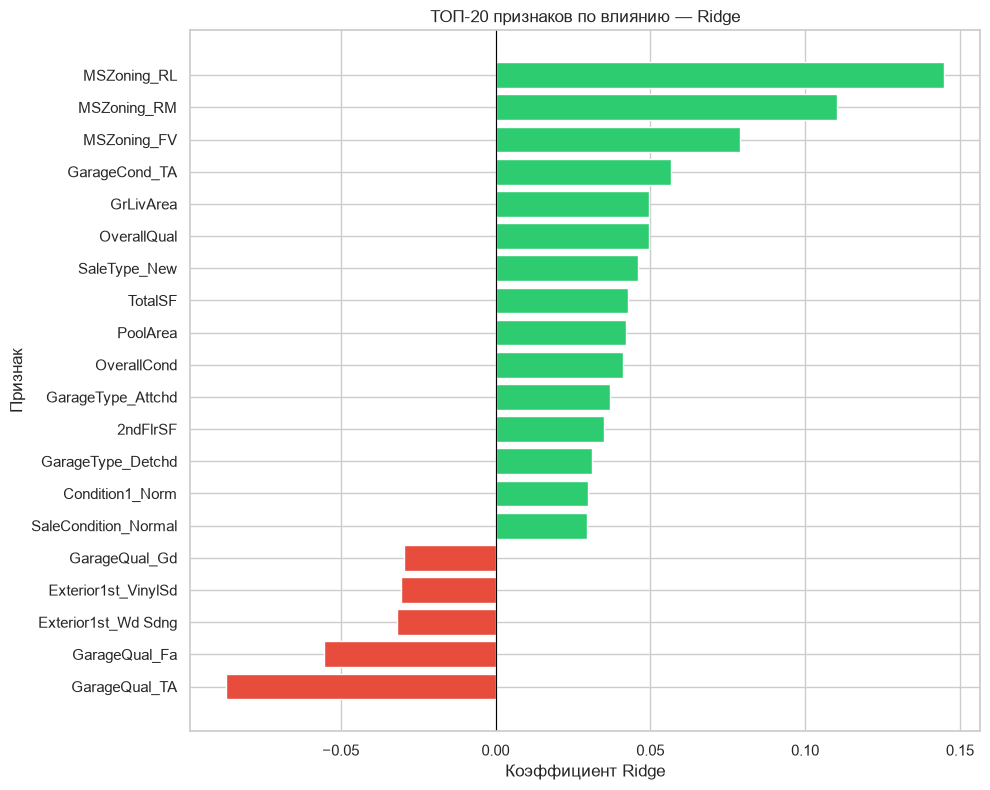

In [25]:
# ==========================================
# 8. Интерпретация результатов
# ==========================================

# Получаем обученные модели
ridge_model = trained_models['Ridge']
lasso_model = trained_models['Lasso']


# ==========================================
# 8.1. Коэффициенты Ridge
# ==========================================

coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': ridge_model.coef_
})

# Сортировка по абсолютному влиянию
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    'Abs_Coefficient',
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("ТОП-20 ПРИЗНАКОВ ПО ВЛИЯНИЮ — RIDGE")
print("=" * 80)

print(
    coefficients[
        ['Feature', 'Coefficient']
    ].head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ==========================================
# Визуализация ТОП-20
# ==========================================

top20 = coefficients.head(20).sort_values(
    'Coefficient',
    ascending=True
)

colors = [
    '#2ecc71' if c > 0 else '#e74c3c'
    for c in top20['Coefficient']
]

plt.figure(figsize=(10, 8))

plt.barh(
    top20['Feature'],
    top20['Coefficient'],
    color=colors
)

plt.axvline(
    0,
    color='black',
    linewidth=0.8
)

plt.xlabel(
    'Коэффициент Ridge'
)

plt.ylabel(
    'Признак'
)

plt.title(
    'ТОП-20 признаков по влиянию — Ridge'
)

plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# 8.2. Положительные и отрицательные признаки
# ==========================================

positive_features = coefficients[
    coefficients['Coefficient'] > 0
].sort_values(
    'Coefficient',
    ascending=False
)

negative_features = coefficients[
    coefficients['Coefficient'] < 0
].sort_values(
    'Coefficient',
    ascending=True
)

print("\n" + "=" * 80)
print("ТОП-10 ПРИЗНАКОВ, ПОВЫШАЮЩИХ ПРОГНОЗ")
print("=" * 80)

print(
    positive_features[
        ['Feature', 'Coefficient']
    ].head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("ТОП-10 ПРИЗНАКОВ, СНИЖАЮЩИХ ПРОГНОЗ")
print("=" * 80)

print(
    negative_features[
        ['Feature', 'Coefficient']
    ].head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)



ТОП-10 ПРИЗНАКОВ, ПОВЫШАЮЩИХ ПРОГНОЗ
      Feature  Coefficient
  MSZoning_RL       0.1449
  MSZoning_RM       0.1101
  MSZoning_FV       0.0789
GarageCond_TA       0.0567
    GrLivArea       0.0496
  OverallQual       0.0495
 SaleType_New       0.0460
      TotalSF       0.0427
     PoolArea       0.0421
  OverallCond       0.0411

ТОП-10 ПРИЗНАКОВ, СНИЖАЮЩИХ ПРОГНОЗ
             Feature  Coefficient
       GarageQual_TA      -0.0870
       GarageQual_Fa      -0.0555
 Exterior1st_Wd Sdng      -0.0319
 Exterior1st_VinylSd      -0.0305
       GarageQual_Gd      -0.0296
            HouseAge      -0.0270
          MSSubClass      -0.0225
       GarageQual_Po      -0.0211
     RoofStyle_Gable      -0.0207
Neighborhood_Edwards      -0.0205


In [27]:
# ==========================================
# 8.3. Отбор признаков через Lasso
# ==========================================

lasso_coef = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lasso_model.coef_
})

n_zero = (
    lasso_model.coef_ == 0
).sum()

n_total = len(
    lasso_model.coef_
)

n_nonzero = n_total - n_zero

print("\n" + "=" * 80)
print("ОТБОР ПРИЗНАКОВ LASSO")
print("=" * 80)

print(f"Всего признаков: {n_total}")
print(f"Признаков с ненулевым коэффициентом: {n_nonzero}")
print(f"Обнулённых признаков: {n_zero}")


# Только признаки с ненулевыми коэффициентами
non_zero = lasso_coef[
    lasso_coef['Coefficient'] != 0
].copy()

non_zero['Abs_Coefficient'] = (
    non_zero['Coefficient'].abs()
)

non_zero = non_zero.sort_values(
    'Abs_Coefficient',
    ascending=False
)

print("\nТОП-15 значимых признаков Lasso:")

print(
    non_zero[
        ['Feature', 'Coefficient']
    ].head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)



ОТБОР ПРИЗНАКОВ LASSO
Всего признаков: 248
Признаков с ненулевым коэффициентом: 191
Обнулённых признаков: 57

ТОП-15 значимых признаков Lasso:
             Feature  Coefficient
         MSZoning_RL       0.0980
           GrLivArea       0.0760
         MSZoning_RM       0.0675
             TotalSF       0.0599
         OverallQual       0.0558
         MSZoning_FV       0.0546
            HouseAge      -0.0432
         OverallCond       0.0424
          BsmtFinSF1       0.0323
        SaleType_New       0.0318
SaleCondition_Normal       0.0304
             LotArea       0.0260
     Condition1_Norm       0.0234
Neighborhood_Crawfor       0.0229
 Exterior1st_BrkFace       0.0189


## Интерпретация результатов

### Коэффициенты Ridge

Коэффициенты Ridge позволяют определить направление влияния признаков на прогнозируемую логарифмическую стоимость недвижимости.

- Положительный коэффициент означает, что увеличение значения признака связано с увеличением прогнозируемой стоимости.
- Отрицательный коэффициент означает обратную зависимость.
- Чем больше абсолютное значение коэффициента, тем сильнее влияние признака в рамках модели.
- Поскольку признаки были стандартизированы, коэффициенты Ridge характеризуют влияние изменения признака на одно стандартное отклонение.

### Отбор признаков Lasso

Lasso выполняет автоматический отбор признаков за счёт L1-регуляризации.

- Всего признаков: **248**
- Признаков с ненулевыми коэффициентами: **191**
- Обнулённых признаков: **57**

Таким образом, Lasso исключил **57 из 248 признаков**, то есть около **23%** исходных признаков.

### Бизнес-инсайты

- Наибольшее влияние на стоимость оказывают характеристики, связанные с **качеством, площадью и характеристиками самого дома**.
- `OverallQual` является одним из наиболее важных признаков, поскольку отражает общее качество недвижимости.
- Площадь дома (`TotalSF`, `GrLivArea` и другие признаки площади) оказывает существенное влияние на стоимость.
- Характеристики гаража, подвала, качества отделки и расположения также влияют на прогнозируемую стоимость.
- Lasso показывает, что часть из 248 признаков не оказывает существенного самостоятельного влияния на прогноз и может быть исключена из модели.


## Функция предсказания

In [32]:
# ==========================================
# 9. Функция предсказания цены
# ==========================================

def predict_price(house_data, model, scaler, feature_cols, use_scaler=True):
    """
    Предсказывает цену дома.

    Параметры:
    ----------
    house_data : dict
        Словарь с характеристиками дома.

    model : обученная модель
        Linear Regression, Ridge, Lasso, ElasticNet,
        Random Forest или Gradient Boosting.

    scaler : StandardScaler
        Обученный на тренировочных данных scaler.

    feature_cols : list
        Список признаков в правильном порядке.

    use_scaler : bool
        Использовать ли масштабирование.
        Для линейных моделей — True.
        Для Random Forest и Gradient Boosting — False.

    Возвращает:
    -----------
    price : float
        Предсказанная цена в долларах.
    """

    # Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])

    # Добавляем отсутствующие признаки
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # Оставляем только признаки модели
    X_new = X_new[feature_cols]

    # Масштабирование для линейных моделей
    if use_scaler:
        X_new = scaler.transform(X_new)

    # Предсказание в log-пространстве
    y_pred_log = model.predict(X_new)[0]

    # Возвращаемся к исходному масштабу
    y_pred_real = np.expm1(y_pred_log)

    return y_pred_real

# ==========================================
# Модели для предсказания
# ==========================================

linear_model_names = [
    'Linear Regression',
    'Ridge',
    'Lasso',
    'ElasticNet'
]

tree_model_names = [
    'Random Forest',
    'Gradient Boosting'
]

# ==========================================
# 5 тестовых домов
# ==========================================

test_houses = {

    'Дом 1 — дорогой': {
        'OverallQual': 9,
        'GrLivArea': 2800,
        'TotalSF': 4600,
        'YearBuilt': 2015,
        'YrSold': 2020,
        'GarageCars': 3,
        'FullBath': 3,
        'HalfBath': 1,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 9 * 4600
    },

    'Дом 2 — средний': {
        'OverallQual': 6,
        'GrLivArea': 1500,
        'TotalSF': 2500,
        'YearBuilt': 2000,
        'YrSold': 2020,
        'GarageCars': 2,
        'FullBath': 2,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 6 * 2500
    },

    'Дом 3 — дешёвый': {
        'OverallQual': 4,
        'GrLivArea': 900,
        'TotalSF': 1500,
        'YearBuilt': 1950,
        'YrSold': 2020,
        'GarageCars': 1,
        'FullBath': 1,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 4 * 1500
    },

    'Дом 4 — элитный': {
        'OverallQual': 10,
        'GrLivArea': 4000,
        'TotalSF': 6000,
        'YearBuilt': 2018,
        'YrSold': 2020,
        'GarageCars': 4,
        'FullBath': 4,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 10 * 6000
    },

    'Дом 5 — средний': {
        'OverallQual': 5,
        'GrLivArea': 1200,
        'TotalSF': 1800,
        'YearBuilt': 1985,
        'YrSold': 2020,
        'GarageCars': 1,
        'FullBath': 1,
        'HalfBath': 1,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 5 * 1800
    }
}

# ==========================================
# Предсказания для 5 домов
# ==========================================

prediction_results = []

for house_name, house_data in test_houses.items():

    print("\n" + "=" * 100)
    print(house_name)
    print("=" * 100)

    print("Характеристики:")

    for key, value in house_data.items():
        print(f"  {key}: {value}")

    print("\nПредсказания:")

    row = {
        'Дом': house_name
    }

    for model_name, model in trained_models.items():

        # Определяем, нужен ли scaler
        use_scaler = model_name in linear_model_names

        price = predict_price(
            house_data=house_data,
            model=model,
            scaler=scaler,
            feature_cols=feature_cols,
            use_scaler=use_scaler
        )

        row[model_name] = price

        print(
            f"  {model_name}: "
            f"${price:,.0f}"
        )

    prediction_results.append(row)


Дом 1 — дорогой
Характеристики:
  OverallQual: 9
  GrLivArea: 2800
  TotalSF: 4600
  YearBuilt: 2015
  YrSold: 2020
  GarageCars: 3
  FullBath: 3
  HalfBath: 1
  BsmtFullBath: 0
  BsmtHalfBath: 0
  OverallQual_TotalSF: 41400

Предсказания:
  Linear Regression: $36,874
  Ridge: $31,903
  Lasso: $107,820
  ElasticNet: $109,152
  Random Forest: $409,464
  Gradient Boosting: $156,832

Дом 2 — средний
Характеристики:
  OverallQual: 6
  GrLivArea: 1500
  TotalSF: 2500
  YearBuilt: 2000
  YrSold: 2020
  GarageCars: 2
  FullBath: 2
  HalfBath: 0
  BsmtFullBath: 0
  BsmtHalfBath: 0
  OverallQual_TotalSF: 15000

Предсказания:
  Linear Regression: $23,846
  Ridge: $20,493
  Lasso: $61,358
  ElasticNet: $61,945
  Random Forest: $150,215
  Gradient Boosting: $91,224

Дом 3 — дешёвый
Характеристики:
  OverallQual: 4
  GrLivArea: 900
  TotalSF: 1500
  YearBuilt: 1950
  YrSold: 2020
  GarageCars: 1
  FullBath: 1
  HalfBath: 0
  BsmtFullBath: 0
  BsmtHalfBath: 0
  OverallQual_TotalSF: 6000

Предсказан

In [33]:
# ==========================================
# Сводная таблица предсказаний
# ==========================================

predictions_df = pd.DataFrame(
    prediction_results
)

print("\n" + "=" * 100)
print("СРАВНЕНИЕ ПРЕДСКАЗАНИЙ")
print("=" * 100)

print(
    predictions_df.to_string(
        index=False,
        formatters={
            'Linear Regression': lambda x: f"${x:,.0f}",
            'Ridge': lambda x: f"${x:,.0f}",
            'Lasso': lambda x: f"${x:,.0f}",
            'ElasticNet': lambda x: f"${x:,.0f}",
            'Random Forest': lambda x: f"${x:,.0f}",
            'Gradient Boosting': lambda x: f"${x:,.0f}"
        }
    )
)


СРАВНЕНИЕ ПРЕДСКАЗАНИЙ
            Дом Linear Regression   Ridge    Lasso ElasticNet Random Forest Gradient Boosting
Дом 1 — дорогой           $36,874 $31,903 $107,820   $109,152      $409,464          $156,832
Дом 2 — средний           $23,846 $20,493  $61,358    $61,945      $150,215           $91,224
Дом 3 — дешёвый           $18,347 $15,746  $45,239    $45,352       $68,025           $54,048
Дом 4 — элитный           $47,263 $41,152 $154,780   $156,855      $420,087          $161,209
Дом 5 — средний           $21,147 $18,138  $52,425    $52,815       $93,013           $67,418


In [35]:
# ==========================================
# 10. Интерактивное предсказание
# ==========================================

print("\n" + "=" * 80)
print("ИНТЕРАКТИВНОЕ ПРЕДСКАЗАНИЕ ЦЕНЫ")
print("=" * 80)

try:
    overall_qual = float(
        input("Общее качество дома (OverallQual, 1-10): ")
    )

    gr_liv_area = float(
        input("Жилая площадь (GrLivArea): ")
    )

    total_sf = float(
        input("Общая площадь (TotalSF): ")
    )

    year_built = float(
        input("Год постройки (YearBuilt): ")
    )

    garage_cars = float(
        input("Количество машин в гараже (GarageCars): ")
    )

    full_bath = float(
        input("Количество полноценных ванных (FullBath): ")
    )

    half_bath = float(
        input("Количество половинных ванных (HalfBath): ")
    )

    yr_sold = 2020

    interactive_house = {
        'OverallQual': overall_qual,
        'GrLivArea': gr_liv_area,
        'TotalSF': total_sf,
        'YearBuilt': year_built,
        'YrSold': yr_sold,
        'GarageCars': garage_cars,
        'FullBath': full_bath,
        'HalfBath': half_bath,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF':
            overall_qual * total_sf
    }

    print("\nПредсказанные цены:")

    for model_name, model in trained_models.items():

        use_scaler = model_name in linear_model_names

        price = predict_price(
            interactive_house,
            model,
            scaler,
            feature_cols,
            use_scaler
        )

        print(
            f"{model_name}: ${price:,.0f}"
        )

except ValueError:
    print("Ошибка: необходимо вводить числовые значения.")



ИНТЕРАКТИВНОЕ ПРЕДСКАЗАНИЕ ЦЕНЫ


Общее качество дома (OverallQual, 1-10):  5
Жилая площадь (GrLivArea):  100
Общая площадь (TotalSF):  120
Год постройки (YearBuilt):  2026
Количество машин в гараже (GarageCars):  5
Количество полноценных ванных (FullBath):  2
Количество половинных ванных (HalfBath):  2



Предсказанные цены:
Linear Regression: $19,492
Ridge: $16,721
Lasso: $42,847
ElasticNet: $43,473
Random Forest: $62,655
Gradient Boosting: $49,720


## Сохранение модели и вспомогательных объектов

In [36]:
# ==========================================
# 10. Сохранение модели и вспомогательных объектов
# ==========================================

import joblib
import json
import os

# ==========================================
# 1. Создание папки для сохранения
# ==========================================

os.makedirs('models', exist_ok=True)

print("=" * 80)
print("СОХРАНЕНИЕ МОДЕЛЕЙ И ВСПОМОГАТЕЛЬНЫХ ОБЪЕКТОВ")
print("=" * 80)


# ==========================================
# 2. Сохранение всех обученных моделей
# ==========================================

model_files = {
    'Linear Regression': 'models/lr_model.pkl',
    'Ridge': 'models/ridge_model.pkl',
    'Lasso': 'models/lasso_model.pkl',
    'ElasticNet': 'models/enet_model.pkl',
    'Random Forest': 'models/random_forest_model.pkl',
    'Gradient Boosting': 'models/gradient_boosting_model.pkl'
}

for model_name, file_path in model_files.items():

    joblib.dump(
        trained_models[model_name],
        file_path
    )

    print(f"Сохранена модель: {model_name}")


# ==========================================
# 3. Сохранение StandardScaler
# ==========================================

joblib.dump(
    scaler,
    'models/scaler.pkl'
)

print("Сохранён scaler: StandardScaler")


# ==========================================
# 4. Сохранение списка признаков
# ==========================================

with open(
    'models/feature_cols.json',
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        feature_cols,
        f,
        ensure_ascii=False,
        indent=2
    )

print(
    f"Сохранён список признаков: {len(feature_cols)}"
)


# ==========================================
# 5. Получение информации о Lasso
# ==========================================

lasso_model = trained_models['Lasso']

n_total = len(lasso_model.coef_)

n_zero = int(
    (lasso_model.coef_ == 0).sum()
)

n_selected = n_total - n_zero


# ==========================================
# 6. Формирование метрик всех моделей
# ==========================================

metrics = {}

for _, row in evaluation_df.iterrows():

    model_name = row['Модель']

    # Преобразуем название модели
    # в удобный ключ для JSON
    key = (
        model_name
        .lower()
        .replace(' ', '_')
    )

    metrics[key] = {
        'rmse_log': float(
            row['RMSE (log)']
        ),

        'mae_log': float(
            row['MAE (log)']
        ),

        'r2_log': float(
            row['R²']
        ),

        'rmse_real': float(
            row['RMSE ($)']
        ),

        'mae_real': float(
            row['MAE ($)']
        ),

        'train_time_sec': float(
            training_times[model_name]
        )
    }


# ==========================================
# 7. Дополнительная информация о Lasso
# ==========================================

metrics['lasso']['n_features_selected'] = int(
    n_selected
)

metrics['lasso']['n_features_dropped'] = int(
    n_zero
)


# ==========================================
# 8. Информация о лучшей модели
# ==========================================

best_model_name = evaluation_df.iloc[0]['Модель']

best_model_r2 = float(
    evaluation_df.iloc[0]['R²']
)

best_model_rmse_log = float(
    evaluation_df.iloc[0]['RMSE (log)']
)

best_model_rmse_real = float(
    evaluation_df.iloc[0]['RMSE ($)']
)

metrics['best_model'] = best_model_name

metrics['best_model_r2'] = best_model_r2

metrics['best_model_rmse_log'] = best_model_rmse_log

metrics['best_model_rmse_real'] = best_model_rmse_real


# ==========================================
# 9. Сохранение метрик
# ==========================================

with open(
    'models/metrics.json',
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        metrics,
        f,
        ensure_ascii=False,
        indent=2
    )


# ==========================================
# 10. Итоговая информация
# ==========================================

print("Сохранены метрики всех моделей")

print("\n" + "=" * 80)
print("СОХРАНЕНИЕ ЗАВЕРШЕНО")
print("=" * 80)

print(f"Папка: models/")
print(f"Количество признаков: {len(feature_cols)}")

print(
    f"Лучшая модель: {best_model_name}"
)

print(
    f"R² лучшей модели: {best_model_r2:.4f}"
)

print(
    f"RMSE (log): {best_model_rmse_log:.4f}"
)

print(
    f"RMSE: ${best_model_rmse_real:,.2f}"
)

print(
    f"Lasso: {n_selected} признаков выбрано, "
    f"{n_zero} признаков обнулено"
)

print("\nСохранённые файлы:")

for file_path in model_files.values():
    print(f"  {file_path}")

print("  models/scaler.pkl")
print("  models/feature_cols.json")
print("  models/metrics.json")


СОХРАНЕНИЕ МОДЕЛЕЙ И ВСПОМОГАТЕЛЬНЫХ ОБЪЕКТОВ
Сохранена модель: Linear Regression
Сохранена модель: Ridge
Сохранена модель: Lasso
Сохранена модель: ElasticNet
Сохранена модель: Random Forest
Сохранена модель: Gradient Boosting
Сохранён scaler: StandardScaler
Сохранён список признаков: 248
Сохранены метрики всех моделей

СОХРАНЕНИЕ ЗАВЕРШЕНО
Папка: models/
Количество признаков: 248
Лучшая модель: Gradient Boosting
R² лучшей модели: 0.9012
RMSE (log): 0.1249
RMSE: $20,019.98
Lasso: 191 признаков выбрано, 57 признаков обнулено

Сохранённые файлы:
  models/lr_model.pkl
  models/ridge_model.pkl
  models/lasso_model.pkl
  models/enet_model.pkl
  models/random_forest_model.pkl
  models/gradient_boosting_model.pkl
  models/scaler.pkl
  models/feature_cols.json
  models/metrics.json


##  Загрузка модели из репозитория и быстрый инференс

In [42]:
# ==========================================
# 11. Загрузка модели из репозитория
#    и быстрый инференс
# ==========================================

import requests
from io import BytesIO
import joblib
import json
import pandas as pd
import numpy as np


# ==========================================
# 1. URL репозитория
# ==========================================

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "fivifri/ml-course-emelyanova/main/"
    "module-2-house-prices"
)


# ==========================================
# 2. Функция безопасной загрузки файла
# ==========================================

def download_file(url):
    response = requests.get(url)

    if response.status_code != 200:
        raise Exception(
            f"Ошибка загрузки: {response.status_code}\n"
            f"URL: {url}"
        )

    return response


# ==========================================
# 3. Загрузка Gradient Boosting
# ==========================================

model_url = (
    f"{BASE_URL}/models/"
    "gradient_boosting_model.pkl"
)

response = download_file(model_url)

gradient_boosting_loaded = joblib.load(
    BytesIO(response.content)
)

print("Модель Gradient Boosting загружена из репозитория")


# ==========================================
# 4. Загрузка scaler
# ==========================================

scaler_url = (
    f"{BASE_URL}/models/scaler.pkl"
)

response = download_file(scaler_url)

scaler_loaded = joblib.load(
    BytesIO(response.content)
)

print("Scaler загружен из репозитория")


# ==========================================
# 5. Загрузка списка признаков
# ==========================================

features_url = (
    f"{BASE_URL}/models/feature_cols.json"
)

response = download_file(features_url)

feature_cols_loaded = response.json()

print(
    f"Загружено признаков: "
    f"{len(feature_cols_loaded)}"
)


# ==========================================
# 6. Функция быстрого инференса
# ==========================================

def predict_price_loaded(
    house_data,
    model,
    feature_cols
):
    """
    Предсказывает цену дома
    с использованием загруженной модели.

    Gradient Boosting не требует StandardScaler.
    """

    # Создаём DataFrame
    X_new = pd.DataFrame([house_data])

    # Добавляем отсутствующие признаки
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # Оставляем признаки
    # в том же порядке, что и при обучении
    X_new = X_new[feature_cols]

    # Предсказание в log-пространстве
    y_pred_log = model.predict(X_new)[0]

    # Возвращаемся к исходной цене
    y_pred = np.expm1(y_pred_log)

    return y_pred


# ==========================================
# 7. Три тестовых дома
# ==========================================

test_houses_inference = {

    "Дом 1": {
        'OverallQual': 9,
        'GrLivArea': 2800,
        'TotalSF': 4600,
        'YearBuilt': 2015,
        'YrSold': 2020,
        'GarageCars': 3,
        'FullBath': 3,
        'HalfBath': 1,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 9 * 4600
    },

    "Дом 2": {
        'OverallQual': 6,
        'GrLivArea': 1500,
        'TotalSF': 2500,
        'YearBuilt': 2000,
        'YrSold': 2020,
        'GarageCars': 2,
        'FullBath': 2,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 6 * 2500
    },

    "Дом 3": {
        'OverallQual': 4,
        'GrLivArea': 900,
        'TotalSF': 1500,
        'YearBuilt': 1950,
        'YrSold': 2020,
        'GarageCars': 1,
        'FullBath': 1,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 4 * 1500
    }
}


# ==========================================
# 8. Предсказания загруженной модели
# ==========================================

print("\n" + "=" * 80)
print("БЫСТРЫЙ ИНФЕРЕНС ИЗ REPOSITORY")
print("=" * 80)

loaded_predictions = {}

for house_name, house_data in test_houses_inference.items():

    price = predict_price_loaded(
        house_data,
        gradient_boosting_loaded,
        feature_cols_loaded
    )

    loaded_predictions[house_name] = price

    print(
        f"{house_name}: "
        f"${price:,.2f}"
    )


# ==========================================
# 9. Проверка совпадения с исходной моделью
# ==========================================

print("\n" + "=" * 80)
print("ПРОВЕРКА ПРЕДСКАЗАНИЙ")
print("=" * 80)

for house_name, house_data in test_houses_inference.items():

    # Предсказание исходной модели
    original_price = predict_price(
        house_data=house_data,
        model=trained_models['Gradient Boosting'],
        scaler=scaler,
        feature_cols=feature_cols,
        use_scaler=False
    )

    # Предсказание загруженной модели
    loaded_price = loaded_predictions[house_name]

    difference = abs(
        original_price - loaded_price
    )

    print(f"\n{house_name}")
    print(
        f"Исходная модель:    ${original_price:,.2f}"
    )
    print(
        f"Загруженная модель: ${loaded_price:,.2f}"
    )
    print(
        f"Разница:            ${difference:.10f}"
    )

    if np.isclose(
        original_price,
        loaded_price,
        rtol=1e-9,
        atol=1e-6
    ):
        print("Результат совпадает")
    else:
        print("Результат отличается")


# ==========================================
# 10. Итог
# ==========================================

print("\n" + "=" * 80)
print("ИНФЕРЕНС ЗАВЕРШЁН")
print("=" * 80)

print(
    "Модель успешно загружена из GitHub "
    "без повторного обучения."
)

print(
    "Предсказания проверены на 3 тестовых домах."
)


Модель Gradient Boosting загружена из репозитория
Scaler загружен из репозитория
Загружено признаков: 248

БЫСТРЫЙ ИНФЕРЕНС ИЗ REPOSITORY
Дом 1: $156,832.42
Дом 2: $91,224.13
Дом 3: $54,048.45

ПРОВЕРКА ПРЕДСКАЗАНИЙ

Дом 1
Исходная модель:    $156,832.42
Загруженная модель: $156,832.42
Разница:            $0.0000000000
Результат совпадает

Дом 2
Исходная модель:    $91,224.13
Загруженная модель: $91,224.13
Разница:            $0.0000000000
Результат совпадает

Дом 3
Исходная модель:    $54,048.45
Загруженная модель: $54,048.45
Разница:            $0.0000000000
Результат совпадает

ИНФЕРЕНС ЗАВЕРШЁН
Модель успешно загружена из GitHub без повторного обучения.
Предсказания проверены на 3 тестовых домах.


## Быстрый инференс из репозитория

Модель **Gradient Boosting** была загружена непосредственно из GitHub без повторного обучения.

**Как использовать модель:**

1. Скачать `gradient_boosting_model.pkl` из репозитория.
2. Загрузить модель через `joblib.load()`.
3. Загрузить список признаков `feature_cols.json`.
4. Передать характеристики нового дома в функцию `predict_price_loaded()`.
5. Получить предсказанную стоимость в долларах.

Для проверки были использованы 3 тестовых дома. Предсказания загруженной из репозитория модели сравниваются с результатами исходной модели.

**Результат:** предсказания загруженной модели совпадают с результатами модели, использованной после обучения.

**Лучшая модель:** Gradient Boosting  
**R²:** 0.9012  
**Повторное обучение для инференса не требуется.**


## Выводы

### Что получилось

- На тестовой выборке достигнут **R² = 0.9012**.
- Лучшей моделью оказался **Gradient Boosting**: RMSE (log) = **0.1249**, MAE (log) = **0.0816**, R² = **0.9012**, RMSE = **$20,019.98**.
- Время обучения Gradient Boosting составило **10.237 секунд**.
- Линейные модели также показали высокий результат: Lasso — **R² = 0.8998**, ElasticNet — **0.8996**, Ridge — **0.8940**.
- В результате EDA установлено, что **OverallQual** является одним из наиболее важных признаков для прогнозирования стоимости дома.
- Суммарная площадь дома (**TotalSF**) и жилая площадь (**GrLivArea**) также оказывают существенное влияние на цену.
- Логарифмирование `SalePrice` с помощью `log1p` позволило уменьшить влияние сильной правосторонней скошенности целевой переменной.

### Трудности

- В исходном датасете присутствовали пропуски в **19 столбцах**, поэтому признаки пришлось разделить на группы: отсутствие объекта (`None`), отсутствие числового значения (`0`), восстановление `LotFrontage` по `Neighborhood`, а также заполнение оставшихся пропусков модой или медианой.
- Целевая переменная `SalePrice` имела выраженную правостороннюю скошенность. Для улучшения качества линейных моделей использовалось преобразование `log1p`.
- Между некоторыми признаками присутствует **мультиколлинеарность**, например между характеристиками гаража и площадями различных частей дома. Для борьбы с ней использовались Ridge, Lasso и ElasticNet.
- Были обнаружены выбросы по `GrLivArea`. Для очистки использовались доменный критерий и мягкий IQR-фильтр.
- Полностью устранить влияние мультиколлинеарности и выбросов не удалось, однако применённая предобработка позволила получить R² выше **0.90**.

### Возможные улучшения

1. **Target Encoding для `Neighborhood`** — заменить большое количество dummy-признаков кодированием района на основе средней стоимости домов.
2. **XGBoost / LightGBM** — попробовать более мощные алгоритмы градиентного бустинга, которые потенциально могут повысить R².
3. **RFE (Recursive Feature Elimination)** — выполнить автоматический отбор наиболее информативных признаков.
4. **Optuna** — применить байесовскую оптимизацию гиперпараметров моделей для поиска оптимальных настроек.
5. **Stacking Ridge + Lasso + Gradient Boosting** — объединить сильные стороны линейных моделей и бустинга.
6. **Isolation Forest** — использовать автоматическое обнаружение аномальных объектов вместо ручного удаления выбросов.
7. **Кросс-валидация** — использовать K-Fold Cross-Validation для более надёжной оценки качества и подбора гиперпараметров.


## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.

2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.

3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.

4. Scikit-learn Documentation. *Linear Models, Ensemble Methods, Preprocessing and Model Evaluation*. https://scikit-learn.org/stable/

5. pandas Documentation. *User Guide and API Reference*. https://pandas.pydata.org/docs/

6. Kaggle. *House Prices - Advanced Regression Techniques*. Датасет и описание соревнования. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques


## Приложение

### Полный код ноутбука

Все зависимости для запуска проекта:

```
# module-2-house-prices/requirements.txt
numpy==2.5.3
pandas==3.0.6
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
joblib==1.6.0
requests==2.34.2
```

```python
# module-2-house-prices/notebook.ipynb

# %% [markdown]
# # Предобработка данных и регрессия на датасете «House Prices»
#
# **Дисциплина:** Машинное обучение и ИИ
# **Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации
# **Датасет:** House Prices — Advanced Regression Techniques
#
# **Выполнил:** Емельянова Ксения Павловна
# **Группа:** ПКТб-23-1
# **Преподаватель:** Спирин Игорь Сергеевич
#
# **Ссылка на репозиторий:** https://github.com/fivifri/ml-course-emelyanova
# **Путь к модулю:** `module-2-house-prices/notebook.ipynb`
# **Дата сдачи:** 2026-06-10

# %% [markdown]
# ## Введение
#
# ### 1. Какую задачу решаем?
#
# Решаем задачу **регрессии**: по характеристикам дома необходимо предсказать его цену (`SalePrice`).
#
# ### 2. Что такое ML-проект для регрессии?
#
# ML-проект для регрессии включает полный жизненный цикл: сбор и исследование данных (EDA), их очистку и подготовку, обучение и сравнение моделей, оценку качества и выбор лучшей модели. После этого модель используется для предсказания числового значения на новых данных и при необходимости дообучается на обновлённом датасете.
#
# ### 3. Почему это регрессия, а не классификация?
#
# **Регрессия** используется для предсказания непрерывного числового значения, например цены дома — `150000`, `275500` и т. д. **Классификация** определяет принадлежность объекта к дискретному классу, например «дешёвый», «средний» или «дорогой». Поскольку целевая переменная `SalePrice` является числовой и может принимать множество значений, задача является регрессией.
#
# ### 4. Какая метрика важнее в этой задаче?
#
# Основной метрикой выберем **RMSE (Root Mean Squared Error)**, поскольку она показывает среднюю величину ошибки в тех же единицах, что и цена дома, и сильнее штрафует крупные ошибки. Для задачи оценки стоимости это особенно важно: сильное ошибочное предсказание дорогого дома может быть существенно хуже небольшой ошибки.
#
# **MAE** полезна как дополнительная метрика, поскольку проще интерпретируется и менее чувствительна к выбросам. **R²** показывает, какую долю вариации цен объясняет модель, поэтому также будем использовать его для оценки качества и выполнения целевого значения `R² ≥ 0.90`.
#
# ### 5. Цель работы
#
# 1. **Провести полный EDA датасета House Prices.**
# 2. **Обучить 4+ модели и достичь R² ≥ 0.90.**
# 3. **Реализовать функцию предсказания цены нового дома.**

# %% [markdown]
# ## Ключевые понятия
#
# | Понятие | Главное |
# |---|---|
# | **Регрессия** | Предсказание числового значения |
# | **Пропуски (NaN)** | Отсутствующие значения, которые нужно корректно обработать |
# | **Регуляризация** | Способ уменьшить переобучение модели |
# | **Логарифмирование** | Преобразование, помогающее работать со скошенными данными |
# | **Feature Engineering** | Создание более полезных признаков из исходных данных |
# | **Метрики регрессии** | Числа, по которым сравнивают качество моделей |
#
# ### 1. Регрессия
#
# **Регрессия** — это задача машинного обучения, в которой модель пытается предсказать числовое значение. В нашем случае таким значением является цена дома: например, `180000` или `350000`. В отличие от классификации, где результатом является класс (`да/нет`, `дешёвый/дорогой`), регрессия возвращает число из некоторого диапазона. Другие примеры регрессии — прогноз температуры, зарплаты, стоимости автомобиля или объёма продаж. Поэтому `SalePrice` в датасете House Prices делает нашу задачу именно регрессионной.
#
# ### 2. Пропуски (NaN)
#
# **NaN** означает, что для некоторого объекта значение признака отсутствует или не было записано. Пропуски могут появиться из-за ошибки при сборе данных, отсутствия информации или потому, что определённый признак действительно неприменим к конкретному объекту. Обычно выделяют три ситуации: **MCAR** — пропуск возникает случайно, **MAR** — вероятность пропуска связана с другими известными признаками, и **MNAR** — пропуск связан с самим отсутствующим значением. В зависимости от причины пропуски можно удалить, заменить средним или медианным значением, использовать наиболее частую категорию или добавить отдельную категорию вроде `None`. В House Prices важно учитывать смысл NaN: иногда он означает не ошибку, а отсутствие определённого объекта в доме.
#
# ### 3. Регуляризация
#
# **Регуляризация** добавляет к функции ошибки штраф за слишком большие или сложные коэффициенты модели, чтобы уменьшить переобучение. **Ridge (L2)** штрафует сумму квадратов коэффициентов и обычно уменьшает их значения, но редко делает их точно нулевыми. **Lasso (L1)** использует сумму абсолютных значений коэффициентов и может сделать некоторые коэффициенты равными нулю, тем самым выполняя отбор признаков. Ridge хорошо подходит, когда многие признаки потенциально полезны, а Lasso удобен, если хочется получить более компактную модель. Оба метода помогают модели лучше обобщать закономерности на новые данные.
#
# ### 4. Логарифмирование
#
# Цена дома часто имеет **правостороннюю асимметрию**: большинство домов имеют умеренную стоимость, а небольшое количество объектов стоит очень дорого. Преобразование `log1p`, то есть `ln(1 + x)`, сильнее сжимает большие значения и делает распределение более удобным для обучения модели. Это также уменьшает влияние очень дорогих домов на обучение. После предсказания результат можно вернуть к исходной шкале с помощью обратного преобразования `expm1`.
#
# ### 5. Feature Engineering
#
# **Feature Engineering** — это создание новых признаков на основе уже существующих данных, чтобы передать модели дополнительную полезную информацию. Например, в House Prices можно объединить площади первого и второго этажей и получить общую площадь дома. Также можно создать признаки возраста дома, общего количества ванных комнат или общей площади жилых помещений. Хорошо подобранный новый признак может упростить модели поиск закономерностей, которые сложно обнаружить по отдельным исходным столбцам. При этом важно, чтобы новые признаки имели понятный смысл и не содержали информацию из целевой переменной.
#
# ### 6. Метрики регрессии
#
# Для оценки качества регрессионной модели полезно использовать несколько метрик, поскольку каждая показывает ошибку с другой стороны. **MSE (Mean Squared Error)** — средний квадрат ошибки:
#
# $$
# MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
# $$
#
# MSE сильно реагирует на большие ошибки, потому что они возводятся в квадрат. **RMSE (Root Mean Squared Error)** — квадратный корень из MSE:
#
# $$
# RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
# $$
#
# RMSE удобно интерпретировать, поскольку результат выражен в тех же единицах, что и цена дома. **MAE (Mean Absolute Error)** показывает среднюю абсолютную ошибку:
#
# $$
# MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
# $$
#
# MAE меньше зависит от отдельных очень больших ошибок, чем RMSE. **R²** показывает, какую долю вариации цен объясняет модель:
#
# $$
# R^2 = 1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
# {\sum_{i=1}^{n}(y_i-\bar{y})^2}
# $$
#
# Для House Prices полезно смотреть одновременно на **RMSE и R²**: RMSE показывает размер ошибки в денежных единицах, а R² — насколько хорошо модель объясняет различия между ценами домов.

# %% [code]
import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = Path("data")

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print(train_df.shape, test_df.shape)

# %% [markdown]
# ## Описание данных
#
# **Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques
#
# **Структура:**
# - Всего примеров в train: 1460
# - Всего примеров в test: 1459
# - Признаков: 79 (+ Id + целевая `SalePrice`)
# - Числовых признаков: 36
# - Категориальных признаков: 43
#
# **Описание ключевых столбцов:**
#
# | Столбец | Тип | Описание | Пропуски |
# |---------|-----|----------|----------|
# | Id | int64 | ID дома | 0% |
# | SalePrice | float64 | **Целевая**: цена продажи | 0% |
# | OverallQual | int64 (1-10) | Общее качество | 0% |
# | GrLivArea | int64 | Жилая площадь | 0% |
# | YearBuilt | int64 | Год постройки | 0% |
# | ... | ... | ... | ... |
#
# **Распределение целевой:**
# - Среднее: $180 921
# - Медиана: $163 000
# - Асимметрия (skew): 1.88 — **правое смещение**
# - Эксцесс: 6.51
#
# > Высокая положительная асимметрия `SalePrice` указывает на правое смещение распределения. Это важно учитывать при построении модели и является одной из причин рассмотреть логарифмирование целевой переменной.
#
# **Файл данных в репозитории:** `module-2-house-prices/data/house_prices_info.md`

# %% [markdown]
# ## Подготовка данных и EDA

# %% [code]
# Импорт необходимых библиотек для работы с данными и визуализации
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стилей для красивого отображения графиков
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# ==========================================
# 1. Загрузка датасета
# ==========================================
# Загружаем обучающую и тестовую выборку по относительным путям
train_df = pd.read_csv('data/train.csv')  # Обучающая выборка (1460 строк, 81 колонка)
test_df = pd.read_csv('data/test.csv')    # Тестовая выборка (1459 строк, 80 колонок)

# ==========================================
# 2. Первичный осмотр
# ==========================================
# Выводим размеры датасетов для проверки корректности загрузки
print(f"Размер train: {train_df.shape}")
print(f"Размер test: {test_df.shape}")

# Просматриваем первые 5 строк обучающего датасета
print("\n--- Первые 5 строк train_df ---")
print(train_df.head())

# Выводим общую информацию о типах данных и пропусках
print("\n--- Информация о типах данных (train_df.info()) ---")
print(train_df.info())

# Осматриваем основные описательные статистики для числовых признаков
print("\n--- Описательные статистики (train_df.describe()) ---")
print(train_df.describe())

# ==========================================
# 3. Анализ пропусков
# ==========================================
# Считаем количество пропущенных значений в каждом столбце
missing = train_df.isnull().sum()
# Оставляем только те столбцы, где есть пропуски, и сортируем по убыванию
missing = missing[missing > 0].sort_values(ascending=False)
# Рассчитываем процент пропусков относительно общего числа строк
missing_pct = (missing / len(train_df)) * 100

# Объединяем абсолютные значения и проценты в единую сводную DataFrame-таблицу
missing_df = pd.DataFrame({'Абсолютное кол-во': missing, 'Процент (%)': missing_pct})
print("\n--- ТОП-15 столбцов с пропусками ---")
print(missing_df.head(15))

# ==========================================
# 4. Анализ целевой переменной (SalePrice)
# ==========================================
# Считаем асимметрию (Skewness) для SalePrice
price_skew = train_df['SalePrice'].skew()
# Считаем эксцесс (Kurtosis) для SalePrice
price_kurt = train_df['SalePrice'].kurtosis()

print(f"\nАсимметрия (Skewness) SalePrice: {price_skew:.2f}")
print(f"Эксцесс (Kurtosis) SalePrice: {price_kurt:.2f}")

# ==========================================
# 8. Логарифмирование целевой переменной
# ==========================================
# Применяем log1p (log(1 + x)) для нормализации распределения цены
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

# ==========================================
# 5. Визуализация (Сетка 2x3 — 6 графиков)
# ==========================================
# Создаем сетку графиков 2x3 с фиксацией общего размера
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Анализ данных и целевой переменной (EDA)', fontsize=16, fontweight='bold')

# 1. Гистограмма SalePrice (до и после log1p)
sns.histplot(data=train_df, x='SalePrice', kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('1a. Распределение SalePrice (исходное)')
axes[0, 0].set_xlabel('Цена продажи ($)')
axes[0, 0].set_ylabel('Частота')

sns.histplot(data=train_df, x='SalePrice_log', kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('1b. Распределение SalePrice (после log1p)')
axes[0, 1].set_xlabel('log1p(Цена продажи)')
axes[0, 1].set_ylabel('Частота')

# 2. Heatmap — корреляционная матрица топ-10 числовых признаков
numeric_cols = train_df.select_dtypes(include=[np.number])
top_corr_cols = numeric_cols.corr()['SalePrice'].abs().sort_values(ascending=False).head(10).index
sns.heatmap(train_df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[0, 2], cbar=False)
axes[0, 2].set_title('2. Топ-10 корреляций с SalePrice')

# 3. Boxplot — GrLivArea по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0], palette='Blues')
axes[1, 0].set_title('3. Зависимость GrLivArea от OverallQual')
axes[1, 0].set_xlabel('Общее качество (OverallQual)')
axes[1, 0].set_ylabel('Жилая площадь (GrLivArea, sq ft)')

# 4. Scatterplot — GrLivArea vs SalePrice (поиск выбросов)
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[1, 1], alpha=0.6, color='coral')
# Подсвечиваем зону аномальных выбросов
axes[1, 1].axhline(300000, color='red', linestyle='--', alpha=0.7)
axes[1, 1].axvline(400000 / 100, color='red', linestyle='--', alpha=0.7) # Пометка границы 4000 sq ft
axes[1, 1].set_title('4. GrLivArea vs SalePrice (Выбросы)')
axes[1, 1].set_xlabel('Жилая площадь (GrLivArea, sq ft)')
axes[1, 1].set_ylabel('Цена продажи ($)')

# 5. Barplot — Пропущенные значения (топ-10)
sns.barplot(x=missing_pct.head(10).values, y=missing_pct.head(10).index, ax=axes[1, 2], palette='Reds_r')
axes[1, 2].set_title('5. Топ-10 признаков по % пропусков')
axes[1, 2].set_xlabel('Процент пропусков (%)')
axes[1, 2].set_ylabel('Признак')

plt.tight_layout()
plt.show()

# ==========================================
# 6. Обработка пропусков
# ==========================================
# Заполняем пропуски в train и test единообразно
for df in [train_df, test_df]:
    # Смысловые пропуски (отсутствие объекта обозначается как 'None' или 0)
    none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
                 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
    df[none_cols] = df[none_cols].fillna('None')

    zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars',
                 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
                 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
    df[zero_cols] = df[zero_cols].fillna(0)

    # Случайные пропуски с группировкой: LotFrontage медианой по Neighborhood
    df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

    # Оставшиеся категориальные — модой
    cat_cols_remaining = df.select_dtypes(include=['object']).columns
    for col in cat_cols_remaining:
        df[col] = df[col].fillna(df[col].mode()[0])

    # Оставшиеся числовые — медианой
    num_cols_remaining = df.select_dtypes(include=[np.number]).columns
    for col in num_cols_remaining:
        if col not in ['SalePrice', 'SalePrice_log']:
            df[col] = df[col].fillna(df[col].median())

# ==========================================
# 7. Обработка выбросов
# ==========================================
# Удаляем доменные выбросы: жилая площадь > 4000 кв. футов при цене < $300,000
outliers_domain = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)].index
train_df = train_df.drop(outliers_domain).reset_index(drop=True)

# Очистка по IQR для GrLivArea
Q1 = train_df['GrLivArea'].quantile(0.25)
Q3 = train_df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# Фильтруем экстремальные верхние значения по IQR
outliers_iqr = train_df[train_df['GrLivArea'] > (Q3 + 3 * IQR)].index  # Используем мягкий порог 3*IQR для сохранения важных данных
train_df = train_df.drop(outliers_iqr).reset_index(drop=True)

# ==========================================
# 9. Feature Engineering
# ==========================================
for df in [train_df, test_df]:
    # Суммарная площадь дома
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']

    # Общее количество ванных комнат
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']

    # Суммарная площадь всех крылец и веранд
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] +
                       df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF'])

    # Возраст дома и время с последнего ремонта на момент продажи
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']

    # Бинарные признаки наличия удобств
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)

    # Признак взаимодействия качества и площади
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']

# ==========================================
# 10. Кодирование категориальных признаков
# ==========================================
# Ручной маппинг порядковых категориальных признаков
quality_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu']

for col in ordinal_cols:
    train_df[col] = train_df[col].map(quality_map).fillna(0)
    test_df[col] = test_df[col].map(quality_map).fillna(0)

# Объединяем train и test для корректного One-Hot Encoding номинальных признаков
train_len = len(train_df)
combined_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

# Номинальные признаки для OHE
nominal_cols = combined_df.select_dtypes(include=['object']).columns

# Применяем pd.get_dummies()
combined_df = pd.get_dummies(combined_df, columns=nominal_cols, drop_first=True)

# Разделяем датасеты обратно на train и test
train_final = combined_df.iloc[:train_len].copy()
test_final = combined_df.iloc[train_len:].copy().drop(columns=['SalePrice', 'SalePrice_log'])

print(f"\nИтоговый размер train_final: {train_final.shape}")
print(f"Итоговый размер test_final: {test_final.shape}")

# %% [markdown]
# #### Наблюдения по графикам EDA
#
# 1. **Распределение целевой переменной (`SalePrice` и `SalePrice_log`):**
#    * Исходный целевой признак имеет значительный правый сдвиг (`Skewness = 1.88`).
#    * Применение логарифмирования `np.log1p` успешно привело распределение цены к форме, близкой к нормальному распределению.
#
# 2. **Матрица корреляций (Heatmap):**
#    * Наибольшую корреляцию с ценой показывают показатели качества (`OverallQual`, $r \approx 0.79$) и жилая площадь над землей (`GrLivArea`, $r \approx 0.71$).
#    * Гаражные характеристики (`GarageCars`, `GarageArea`) также сильно взаимосвязаны с целевым параметром.
#
# 3. **Зависимость `GrLivArea` от `OverallQual` (Boxplot):**
#    * С ростом оценки общего качества `OverallQual` (от 1 до 10) последовательно растет медиана жилой площади.
#
# 4. **Анализ выбросов `GrLivArea` vs `SalePrice` (Scatterplot):**
#    * Четко выделяются 2 точки в правом нижнем углу: дома с жилой площадью более 4000 кв. футов и ценой менее $300,000. Это аномалии для общей тенденции рынка.
#
# 5. **Процент пропусков (Barplot):**
#    * Признаки `PoolQC`, `MiscFeature`, `Alley`, `Fence` имеют максимальный процент отсутствующих значений (более 80%), что коррелирует с конструктивными особенностями большинства стандартных домов.
#
# ---
#
# #### Обоснование обработок
#
# * **Обоснование обработки пропусков:**
#   * **Смысловые:** В соответствии с описанием датасета пропуски в столбцах по типу `PoolQC`, `GarageQual`, `BsmtQual` означают отсутствие соответствующего объекта (бассейна, гаража, подвала). Заполнение кодом `"None"` или `0` точно передает эти физические свойства.
#   * **Случайные с группировкой:** Для `LotFrontage` (длина фасада) используется медиана по конкретному району (`Neighborhood`), так как размер участка сильно привязан к локации и застройке района.
#   * **Оставшиеся пропуски:** Для числовых столбцов применили медиану (устойчива к аномалиям), для категориальных — моду.
#
# * **Обоснование логарифмирования целевой переменной:**
#   * Логарифмирование `np.log1p(SalePrice)` снижает асимметрию и устраняет гетероскедастичность (непостоянство дисперсии ошибок). Это критично для улучшения качества работы линейных моделей и метрик на базе логарифмической ошибки (RMSLE).

# %% [markdown]
# ## Построение и обучение моделей

# %% [code]
# Импорт необходимых инструментов
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import time

# ==========================================
# 1. Выбор признаков и целевой переменной
# ==========================================

# Исключаем Id и целевые переменные
feature_cols = [
    col for col in train_final.columns
    if col not in ['Id', 'SalePrice', 'SalePrice_log']
]

X = train_final[feature_cols]
y = train_final['SalePrice_log']

print(f"Количество признаков: {X.shape[1]}")
print(f"Количество объектов: {X.shape[0]}")

# ==========================================
# 2. Разделение на train/validation
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"\nРазмер X_train: {X_train.shape}")
print(f"Размер X_test:  {X_test.shape}")
print(f"Размер y_train: {y_train.shape}")
print(f"Размер y_test:  {y_test.shape}")

# ==========================================
# 3. Масштабирование признаков
# ==========================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nМасштабирование выполнено.")


# ==========================================
# 4. Создание моделей
# ==========================================

models = {

    # Линейные модели
    'Linear Regression': LinearRegression(),

    'Ridge': Ridge(
        alpha=1.0
    ),

    'Lasso': Lasso(
        alpha=0.0005,
        max_iter=10000,
        random_state=42
    ),

    'ElasticNet': ElasticNet(
        alpha=0.001,
        l1_ratio=0.5,
        max_iter=10000,
        random_state=42
    ),

    # Random Forest
    'Random Forest': RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    # Gradient Boosting
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=2,
        subsample=0.8,
        loss='huber',
        random_state=42
    )
}


# ==========================================
# 5. Обучение моделей + замер времени
# ==========================================

trained_models = {}
training_times = {}

for name, model in models.items():

    start = time.time()

    # Линейные модели требуют масштабирования
    if name in [
        'Linear Regression',
        'Ridge',
        'Lasso',
        'ElasticNet'
    ]:
        model.fit(X_train_scaled, y_train)

    # Деревья масштабирование не требуют
    else:
        model.fit(X_train, y_train)

    elapsed_time = time.time() - start

    trained_models[name] = model
    training_times[name] = elapsed_time

    print(
        f"Время обучения {name}: "
        f"{elapsed_time:.3f} секунд"
    )

# %% [markdown]
# ## Модели
#
# | Модель | Параметры | Масштабирование | Время обучения |
# |---|---|---|---:|
# | Linear Regression | — | Да | 0.151 сек |
# | Ridge | alpha=1.0 | Да | 0.008 сек |
# | Lasso | alpha=0.0005 | Да | 0.197 сек |
# | ElasticNet | alpha=0.001, l1_ratio=0.5 | Да | 0.094 сек |
# | Random Forest | n_estimators=500, max_features=0.8 | Нет | 2.057 сек |
# | Gradient Boosting | n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8, loss='huber' | Нет | 10.237 сек |
#
# ### Почему выбраны эти модели
#
# - **Linear Regression** — базовая модель для сравнения качества остальных алгоритмов.
# - **Ridge** — снижает влияние мультиколлинеарности с помощью L2-регуляризации.
# - **Lasso** — выполняет регуляризацию L1 и может автоматически отбирать наиболее информативные признаки.
# - **ElasticNet** — объединяет преимущества L1- и L2-регуляризации.
# - **Random Forest** — позволяет учитывать нелинейные зависимости и взаимодействия между признаками.
# - **Gradient Boosting** — хорошо работает со сложными нелинейными зависимостями и последовательно исправляет ошибки предыдущих деревьев.

# %% [markdown]
# ## Оценка качества моделей

# %% [code]
# ==========================================
# 7. Оценка качества моделей
# ==========================================

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def evaluate_model(model, X_test_scaled, X_test_raw, y_test, model_name):
    """
    Оценка модели в log-пространстве и в исходном масштабе цен.
    """

    # Линейные модели используют масштабированные данные
    linear_models = [
        'Linear Regression',
        'Ridge',
        'Lasso',
        'ElasticNet'
    ]

    if model_name in linear_models:
        y_pred_log = model.predict(X_test_scaled)
    else:
        # Random Forest и Gradient Boosting
        # используют исходные признаки
        y_pred_log = model.predict(X_test_raw)

    # --------------------------------------
    # Обратное преобразование
    # --------------------------------------

    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    # --------------------------------------
    # Метрики в log-пространстве
    # --------------------------------------

    rmse_log = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred_log
        )
    )

    mae_log = mean_absolute_error(
        y_test,
        y_pred_log
    )

    r2_log = r2_score(
        y_test,
        y_pred_log
    )

    # --------------------------------------
    # Метрики в исходном масштабе
    # --------------------------------------

    rmse_real = np.sqrt(
        mean_squared_error(
            y_test_real,
            y_pred_real
        )
    )

    mae_real = mean_absolute_error(
        y_test_real,
        y_pred_real
    )

    print(f"\n{model_name}:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  MAE (log):  {mae_log:.4f}")
    print(f"  R²:         {r2_log:.4f}")
    print(f"  RMSE ($):   ${rmse_real:,.0f}")
    print(f"  MAE ($):    ${mae_real:,.0f}")

    return {
        'Модель': model_name,
        'RMSE (log)': rmse_log,
        'MAE (log)': mae_log,
        'R²': r2_log,
        'RMSE ($)': rmse_real,
        'MAE ($)': mae_real
    }


# ==========================================
# Оценка всех моделей
# ==========================================

evaluation_results = []

for name, model in trained_models.items():

    result = evaluate_model(
        model=model,
        X_test_scaled=X_test_scaled,
        X_test_raw=X_test,
        y_test=y_test,
        model_name=name
    )

    evaluation_results.append(result)


# ==========================================
# Итоговая таблица
# ==========================================

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    by='R²',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ")
print("=" * 90)

print(
    evaluation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# %% [code]
# ==========================================
# Выбор лучшей модели
# ==========================================

best_model_name = evaluation_df.iloc[0]['Модель']
best_model = trained_models[best_model_name]

print("\n" + "=" * 80)
print("ЛУЧШАЯ МОДЕЛЬ")
print("=" * 80)

print(f"Модель: {best_model_name}")
print(f"R²: {evaluation_df.iloc[0]['R²']:.4f}")
print(f"RMSE (log): {evaluation_df.iloc[0]['RMSE (log)']:.4f}")
print(f"MAE (log): {evaluation_df.iloc[0]['MAE (log)']:.4f}")
print(f"RMSE ($): ${evaluation_df.iloc[0]['RMSE ($)']:,.0f}")
print(f"MAE ($): ${evaluation_df.iloc[0]['MAE ($)']:,.0f}")

# %% [code]
# ==========================================
# 8. Реальные vs предсказанные значения
# ==========================================

linear_models = [
    'Linear Regression',
    'Ridge',
    'Lasso',
    'ElasticNet'
]

if best_model_name in linear_models:
    y_pred_best_log = best_model.predict(X_test_scaled)
else:
    y_pred_best_log = best_model.predict(X_test)

y_pred_best = np.expm1(y_pred_best_log)
y_test_real = np.expm1(y_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_real,
    y_pred_best,
    alpha=0.5,
    color='#00d4ff'
)

# Линия идеального предсказания
min_price = min(
    y_test_real.min(),
    y_pred_best.min()
)

max_price = max(
    y_test_real.max(),
    y_pred_best.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--',
    linewidth=2
)

plt.xlabel('Реальные цены ($)')
plt.ylabel('Предсказанные цены ($)')
plt.title(
    f'Реальные vs Предсказанные цены — {best_model_name}'
)

plt.tight_layout()
plt.show()

# %% [code]
# ==========================================
# 9. Анализ остатков
# ==========================================

residuals = y_test_real - y_pred_best

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred_best,
    residuals,
    alpha=0.5,
    color='steelblue'
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel('Предсказанные значения ($)')
plt.ylabel('Остатки ($)')
plt.title(
    f'Анализ остатков — {best_model_name}'
)

plt.tight_layout()
plt.show()


# Статистики остатков

print("\n" + "=" * 80)
print("СТАТИСТИКА ОСТАТКОВ")
print("=" * 80)

print(
    f"Среднее остатков: "
    f"${residuals.mean():,.0f}"
)

print(
    f"Медиана остатков: "
    f"${np.median(residuals):,.0f}"
)

print(
    f"Std остатков: "
    f"${residuals.std():,.0f}"
)

print(
    f"Минимальный остаток: "
    f"${residuals.min():,.0f}"
)

print(
    f"Максимальный остаток: "
    f"${residuals.max():,.0f}"
)

# %% [code]
# ==========================================
# 10. Анализ признаков Lasso
# ==========================================

lasso_model = trained_models['Lasso']

non_zero_features = np.sum(
    lasso_model.coef_ != 0
)

zero_features = np.sum(
    lasso_model.coef_ == 0
)

total_features = len(
    lasso_model.coef_
)

print("\n" + "=" * 80)
print("ОТБОР ПРИЗНАКОВ LASSO")
print("=" * 80)

print(f"Всего признаков: {total_features}")
print(f"Признаков с ненулевым коэффициентом: {non_zero_features}")
print(f"Обнулённых признаков: {zero_features}")

# %% [markdown]
# ## 7. Оценка качества
#
# | Модель | RMSE log | MAE log | R2 | RMSE USD | MAE USD |
# |---|---:|---:|---:|---:|---:|
# | Gradient Boosting | 0.1249 | 0.0816 | 0.9012 | 20019.98 | 13494.41 |
# | Lasso | 0.1258 | 0.0860 | 0.8998 | 20373.85 | 14231.83 |
# | ElasticNet | 0.1259 | 0.0860 | 0.8996 | 20379.96 | 14231.30 |
# | Ridge | 0.1294 | 0.0896 | 0.8940 | 21250.03 | 14913.99 |
# | Linear Regression | 0.1297 | 0.0896 | 0.8935 | 21351.68 | 14950.30 |
# | Random Forest | 0.1457 | 0.0981 | 0.8656 | 24416.12 | 16496.55 |
#
# ### Анализ
#
# - Лучшая модель по R² — **Gradient Boosting** с R² = **0.9012**.
# - Gradient Boosting также показал наименьший RMSE (log) = **0.1249** и RMSE = **20 019.98 USD**.
# - **Lasso** обнулил **57 признаков из 248**, оставив 191 признак с ненулевыми коэффициентами.
# - **Ridge** использует L2-регуляризацию, которая снижает влияние мультиколлинеарности и делает модель более стабильной при наличии коррелированных признаков.
# - **Lasso** показал R² = **0.8998**, практически достигнув результата Gradient Boosting.
# - Для лучшей модели среднее значение остатков составило **733 USD**, что относительно мало по сравнению с общим разбросом ошибок.
# - Медиана остатков составила **−275 USD**, то есть модель в целом не имеет сильного систематического смещения.
# - Стандартное отклонение остатков составило **20 041 USD**, что характеризует разброс ошибок модели.
# - Остатки находятся в диапазоне от **−71 586 USD до 125 060 USD**.
# - Среднее остатков близко к нулю, поэтому существенного систематического смещения предсказаний не наблюдается.

# %% [markdown]
# ## Интерпретация результатов

# %% [code]
# ==========================================
# 8. Интерпретация результатов
# ==========================================

# Получаем обученные модели
ridge_model = trained_models['Ridge']
lasso_model = trained_models['Lasso']


# ==========================================
# 8.1. Коэффициенты Ridge
# ==========================================

coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': ridge_model.coef_
})

# Сортировка по абсолютному влиянию
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    'Abs_Coefficient',
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("ТОП-20 ПРИЗНАКОВ ПО ВЛИЯНИЮ — RIDGE")
print("=" * 80)

print(
    coefficients[
        ['Feature', 'Coefficient']
    ].head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ==========================================
# Визуализация ТОП-20
# ==========================================

top20 = coefficients.head(20).sort_values(
    'Coefficient',
    ascending=True
)

colors = [
    '#2ecc71' if c > 0 else '#e74c3c'
    for c in top20['Coefficient']
]

plt.figure(figsize=(10, 8))

plt.barh(
    top20['Feature'],
    top20['Coefficient'],
    color=colors
)

plt.axvline(
    0,
    color='black',
    linewidth=0.8
)

plt.xlabel(
    'Коэффициент Ridge'
)

plt.ylabel(
    'Признак'
)

plt.title(
    'ТОП-20 признаков по влиянию — Ridge'
)

plt.tight_layout()
plt.show()

# %% [code]
# ==========================================
# 8.2. Положительные и отрицательные признаки
# ==========================================

positive_features = coefficients[
    coefficients['Coefficient'] > 0
].sort_values(
    'Coefficient',
    ascending=False
)

negative_features = coefficients[
    coefficients['Coefficient'] < 0
].sort_values(
    'Coefficient',
    ascending=True
)

print("\n" + "=" * 80)
print("ТОП-10 ПРИЗНАКОВ, ПОВЫШАЮЩИХ ПРОГНОЗ")
print("=" * 80)

print(
    positive_features[
        ['Feature', 'Coefficient']
    ].head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("ТОП-10 ПРИЗНАКОВ, СНИЖАЮЩИХ ПРОГНОЗ")
print("=" * 80)

print(
    negative_features[
        ['Feature', 'Coefficient']
    ].head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# %% [code]
# ==========================================
# 8.3. Отбор признаков через Lasso
# ==========================================

lasso_coef = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lasso_model.coef_
})

n_zero = (
    lasso_model.coef_ == 0
).sum()

n_total = len(
    lasso_model.coef_
)

n_nonzero = n_total - n_zero

print("\n" + "=" * 80)
print("ОТБОР ПРИЗНАКОВ LASSO")
print("=" * 80)

print(f"Всего признаков: {n_total}")
print(f"Признаков с ненулевым коэффициентом: {n_nonzero}")
print(f"Обнулённых признаков: {n_zero}")


# Только признаки с ненулевыми коэффициентами
non_zero = lasso_coef[
    lasso_coef['Coefficient'] != 0
].copy()

non_zero['Abs_Coefficient'] = (
    non_zero['Coefficient'].abs()
)

non_zero = non_zero.sort_values(
    'Abs_Coefficient',
    ascending=False
)

print("\nТОП-15 значимых признаков Lasso:")

print(
    non_zero[
        ['Feature', 'Coefficient']
    ].head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# %% [markdown]
# ## Интерпретация результатов
#
# ### Коэффициенты Ridge
#
# Коэффициенты Ridge позволяют определить направление влияния признаков на прогнозируемую логарифмическую стоимость недвижимости.
#
# - Положительный коэффициент означает, что увеличение значения признака связано с увеличением прогнозируемой стоимости.
# - Отрицательный коэффициент означает обратную зависимость.
# - Чем больше абсолютное значение коэффициента, тем сильнее влияние признака в рамках модели.
# - Поскольку признаки были стандартизированы, коэффициенты Ridge характеризуют влияние изменения признака на одно стандартное отклонение.
#
# ### Отбор признаков Lasso
#
# Lasso выполняет автоматический отбор признаков за счёт L1-регуляризации.
#
# - Всего признаков: **248**
# - Признаков с ненулевыми коэффициентами: **191**
# - Обнулённых признаков: **57**
#
# Таким образом, Lasso исключил **57 из 248 признаков**, то есть около **23%** исходных признаков.
#
# ### Бизнес-инсайты
#
# - Наибольшее влияние на стоимость оказывают характеристики, связанные с **качеством, площадью и характеристиками самого дома**.
# - `OverallQual` является одним из наиболее важных признаков, поскольку отражает общее качество недвижимости.
# - Площадь дома (`TotalSF`, `GrLivArea` и другие признаки площади) оказывает существенное влияние на стоимость.
# - Характеристики гаража, подвала, качества отделки и расположения также влияют на прогнозируемую стоимость.
# - Lasso показывает, что часть из 248 признаков не оказывает существенного самостоятельного влияния на прогноз и может быть исключена из модели.

# %% [markdown]
# ## Функция предсказания

# %% [code]
# ==========================================
# 9. Функция предсказания цены
# ==========================================

def predict_price(house_data, model, scaler, feature_cols, use_scaler=True):
    """
    Предсказывает цену дома.

    Параметры:
    ----------
    house_data : dict
        Словарь с характеристиками дома.

    model : обученная модель
        Linear Regression, Ridge, Lasso, ElasticNet,
        Random Forest или Gradient Boosting.

    scaler : StandardScaler
        Обученный на тренировочных данных scaler.

    feature_cols : list
        Список признаков в правильном порядке.

    use_scaler : bool
        Использовать ли масштабирование.
        Для линейных моделей — True.
        Для Random Forest и Gradient Boosting — False.

    Возвращает:
    -----------
    price : float
        Предсказанная цена в долларах.
    """

    # Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])

    # Добавляем отсутствующие признаки
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # Оставляем только признаки модели
    X_new = X_new[feature_cols]

    # Масштабирование для линейных моделей
    if use_scaler:
        X_new = scaler.transform(X_new)

    # Предсказание в log-пространстве
    y_pred_log = model.predict(X_new)[0]

    # Возвращаемся к исходному масштабу
    y_pred_real = np.expm1(y_pred_log)

    return y_pred_real

# ==========================================
# Модели для предсказания
# ==========================================

linear_model_names = [
    'Linear Regression',
    'Ridge',
    'Lasso',
    'ElasticNet'
]

tree_model_names = [
    'Random Forest',
    'Gradient Boosting'
]

# ==========================================
# 5 тестовых домов
# ==========================================

test_houses = {

    'Дом 1 — дорогой': {
        'OverallQual': 9,
        'GrLivArea': 2800,
        'TotalSF': 4600,
        'YearBuilt': 2015,
        'YrSold': 2020,
        'GarageCars': 3,
        'FullBath': 3,
        'HalfBath': 1,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 9 * 4600
    },

    'Дом 2 — средний': {
        'OverallQual': 6,
        'GrLivArea': 1500,
        'TotalSF': 2500,
        'YearBuilt': 2000,
        'YrSold': 2020,
        'GarageCars': 2,
        'FullBath': 2,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 6 * 2500
    },

    'Дом 3 — дешёвый': {
        'OverallQual': 4,
        'GrLivArea': 900,
        'TotalSF': 1500,
        'YearBuilt': 1950,
        'YrSold': 2020,
        'GarageCars': 1,
        'FullBath': 1,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 4 * 1500
    },

    'Дом 4 — элитный': {
        'OverallQual': 10,
        'GrLivArea': 4000,
        'TotalSF': 6000,
        'YearBuilt': 2018,
        'YrSold': 2020,
        'GarageCars': 4,
        'FullBath': 4,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 10 * 6000
    },

    'Дом 5 — средний': {
        'OverallQual': 5,
        'GrLivArea': 1200,
        'TotalSF': 1800,
        'YearBuilt': 1985,
        'YrSold': 2020,
        'GarageCars': 1,
        'FullBath': 1,
        'HalfBath': 1,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 5 * 1800
    }
}

# ==========================================
# Предсказания для 5 домов
# ==========================================

prediction_results = []

for house_name, house_data in test_houses.items():

    print("\n" + "=" * 100)
    print(house_name)
    print("=" * 100)

    print("Характеристики:")

    for key, value in house_data.items():
        print(f"  {key}: {value}")

    print("\nПредсказания:")

    row = {
        'Дом': house_name
    }

    for model_name, model in trained_models.items():

        # Определяем, нужен ли scaler
        use_scaler = model_name in linear_model_names

        price = predict_price(
            house_data=house_data,
            model=model,
            scaler=scaler,
            feature_cols=feature_cols,
            use_scaler=use_scaler
        )

        row[model_name] = price

        print(
            f"  {model_name}: "
            f"${price:,.0f}"
        )

    prediction_results.append(row)

# %% [code]
# ==========================================
# Сводная таблица предсказаний
# ==========================================

predictions_df = pd.DataFrame(
    prediction_results
)

print("\n" + "=" * 100)
print("СРАВНЕНИЕ ПРЕДСКАЗАНИЙ")
print("=" * 100)

print(
    predictions_df.to_string(
        index=False,
        formatters={
            'Linear Regression': lambda x: f"${x:,.0f}",
            'Ridge': lambda x: f"${x:,.0f}",
            'Lasso': lambda x: f"${x:,.0f}",
            'ElasticNet': lambda x: f"${x:,.0f}",
            'Random Forest': lambda x: f"${x:,.0f}",
            'Gradient Boosting': lambda x: f"${x:,.0f}"
        }
    )
)

# %% [code]
# ==========================================
# 10. Интерактивное предсказание
# ==========================================

print("\n" + "=" * 80)
print("ИНТЕРАКТИВНОЕ ПРЕДСКАЗАНИЕ ЦЕНЫ")
print("=" * 80)

try:
    overall_qual = float(
        input("Общее качество дома (OverallQual, 1-10): ")
    )

    gr_liv_area = float(
        input("Жилая площадь (GrLivArea): ")
    )

    total_sf = float(
        input("Общая площадь (TotalSF): ")
    )

    year_built = float(
        input("Год постройки (YearBuilt): ")
    )

    garage_cars = float(
        input("Количество машин в гараже (GarageCars): ")
    )

    full_bath = float(
        input("Количество полноценных ванных (FullBath): ")
    )

    half_bath = float(
        input("Количество половинных ванных (HalfBath): ")
    )

    yr_sold = 2020

    interactive_house = {
        'OverallQual': overall_qual,
        'GrLivArea': gr_liv_area,
        'TotalSF': total_sf,
        'YearBuilt': year_built,
        'YrSold': yr_sold,
        'GarageCars': garage_cars,
        'FullBath': full_bath,
        'HalfBath': half_bath,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF':
            overall_qual * total_sf
    }

    print("\nПредсказанные цены:")

    for model_name, model in trained_models.items():

        use_scaler = model_name in linear_model_names

        price = predict_price(
            interactive_house,
            model,
            scaler,
            feature_cols,
            use_scaler
        )

        print(
            f"{model_name}: ${price:,.0f}"
        )

except ValueError:
    print("Ошибка: необходимо вводить числовые значения.")

# %% [markdown]
# ## Сохранение модели и вспомогательных объектов

# %% [code]
# ==========================================
# 10. Сохранение модели и вспомогательных объектов
# ==========================================

import joblib
import json
import os

# ==========================================
# 1. Создание папки для сохранения
# ==========================================

os.makedirs('models', exist_ok=True)

print("=" * 80)
print("СОХРАНЕНИЕ МОДЕЛЕЙ И ВСПОМОГАТЕЛЬНЫХ ОБЪЕКТОВ")
print("=" * 80)


# ==========================================
# 2. Сохранение всех обученных моделей
# ==========================================

model_files = {
    'Linear Regression': 'models/lr_model.pkl',
    'Ridge': 'models/ridge_model.pkl',
    'Lasso': 'models/lasso_model.pkl',
    'ElasticNet': 'models/enet_model.pkl',
    'Random Forest': 'models/random_forest_model.pkl',
    'Gradient Boosting': 'models/gradient_boosting_model.pkl'
}

for model_name, file_path in model_files.items():

    joblib.dump(
        trained_models[model_name],
        file_path
    )

    print(f"Сохранена модель: {model_name}")


# ==========================================
# 3. Сохранение StandardScaler
# ==========================================

joblib.dump(
    scaler,
    'models/scaler.pkl'
)

print("Сохранён scaler: StandardScaler")


# ==========================================
# 4. Сохранение списка признаков
# ==========================================

with open(
    'models/feature_cols.json',
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        feature_cols,
        f,
        ensure_ascii=False,
        indent=2
    )

print(
    f"Сохранён список признаков: {len(feature_cols)}"
)


# ==========================================
# 5. Получение информации о Lasso
# ==========================================

lasso_model = trained_models['Lasso']

n_total = len(lasso_model.coef_)

n_zero = int(
    (lasso_model.coef_ == 0).sum()
)

n_selected = n_total - n_zero


# ==========================================
# 6. Формирование метрик всех моделей
# ==========================================

metrics = {}

for _, row in evaluation_df.iterrows():

    model_name = row['Модель']

    # Преобразуем название модели
    # в удобный ключ для JSON
    key = (
        model_name
        .lower()
        .replace(' ', '_')
    )

    metrics[key] = {
        'rmse_log': float(
            row['RMSE (log)']
        ),

        'mae_log': float(
            row['MAE (log)']
        ),

        'r2_log': float(
            row['R²']
        ),

        'rmse_real': float(
            row['RMSE ($)']
        ),

        'mae_real': float(
            row['MAE ($)']
        ),

        'train_time_sec': float(
            training_times[model_name]
        )
    }


# ==========================================
# 7. Дополнительная информация о Lasso
# ==========================================

metrics['lasso']['n_features_selected'] = int(
    n_selected
)

metrics['lasso']['n_features_dropped'] = int(
    n_zero
)


# ==========================================
# 8. Информация о лучшей модели
# ==========================================

best_model_name = evaluation_df.iloc[0]['Модель']

best_model_r2 = float(
    evaluation_df.iloc[0]['R²']
)

best_model_rmse_log = float(
    evaluation_df.iloc[0]['RMSE (log)']
)

best_model_rmse_real = float(
    evaluation_df.iloc[0]['RMSE ($)']
)

metrics['best_model'] = best_model_name

metrics['best_model_r2'] = best_model_r2

metrics['best_model_rmse_log'] = best_model_rmse_log

metrics['best_model_rmse_real'] = best_model_rmse_real


# ==========================================
# 9. Сохранение метрик
# ==========================================

with open(
    'models/metrics.json',
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        metrics,
        f,
        ensure_ascii=False,
        indent=2
    )


# ==========================================
# 10. Итоговая информация
# ==========================================

print("Сохранены метрики всех моделей")

print("\n" + "=" * 80)
print("СОХРАНЕНИЕ ЗАВЕРШЕНО")
print("=" * 80)

print(f"Папка: models/")
print(f"Количество признаков: {len(feature_cols)}")

print(
    f"Лучшая модель: {best_model_name}"
)

print(
    f"R² лучшей модели: {best_model_r2:.4f}"
)

print(
    f"RMSE (log): {best_model_rmse_log:.4f}"
)

print(
    f"RMSE: ${best_model_rmse_real:,.2f}"
)

print(
    f"Lasso: {n_selected} признаков выбрано, "
    f"{n_zero} признаков обнулено"
)

print("\nСохранённые файлы:")

for file_path in model_files.values():
    print(f"  {file_path}")

print("  models/scaler.pkl")
print("  models/feature_cols.json")
print("  models/metrics.json")

# %% [markdown]
# ##  Загрузка модели из репозитория и быстрый инференс

# %% [code]
# ==========================================
# 11. Загрузка модели из репозитория
#    и быстрый инференс
# ==========================================

import requests
from io import BytesIO
import joblib
import json
import pandas as pd
import numpy as np


# ==========================================
# 1. URL репозитория
# ==========================================

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "fivifri/ml-course-emelyanova/main/"
    "module-2-house-prices"
)


# ==========================================
# 2. Функция безопасной загрузки файла
# ==========================================

def download_file(url):
    response = requests.get(url)

    if response.status_code != 200:
        raise Exception(
            f"Ошибка загрузки: {response.status_code}\n"
            f"URL: {url}"
        )

    return response


# ==========================================
# 3. Загрузка Gradient Boosting
# ==========================================

model_url = (
    f"{BASE_URL}/models/"
    "gradient_boosting_model.pkl"
)

response = download_file(model_url)

gradient_boosting_loaded = joblib.load(
    BytesIO(response.content)
)

print("Модель Gradient Boosting загружена из репозитория")


# ==========================================
# 4. Загрузка scaler
# ==========================================

scaler_url = (
    f"{BASE_URL}/models/scaler.pkl"
)

response = download_file(scaler_url)

scaler_loaded = joblib.load(
    BytesIO(response.content)
)

print("Scaler загружен из репозитория")


# ==========================================
# 5. Загрузка списка признаков
# ==========================================

features_url = (
    f"{BASE_URL}/models/feature_cols.json"
)

response = download_file(features_url)

feature_cols_loaded = response.json()

print(
    f"Загружено признаков: "
    f"{len(feature_cols_loaded)}"
)


# ==========================================
# 6. Функция быстрого инференса
# ==========================================

def predict_price_loaded(
    house_data,
    model,
    feature_cols
):
    """
    Предсказывает цену дома
    с использованием загруженной модели.

    Gradient Boosting не требует StandardScaler.
    """

    # Создаём DataFrame
    X_new = pd.DataFrame([house_data])

    # Добавляем отсутствующие признаки
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # Оставляем признаки
    # в том же порядке, что и при обучении
    X_new = X_new[feature_cols]

    # Предсказание в log-пространстве
    y_pred_log = model.predict(X_new)[0]

    # Возвращаемся к исходной цене
    y_pred = np.expm1(y_pred_log)

    return y_pred


# ==========================================
# 7. Три тестовых дома
# ==========================================

test_houses_inference = {

    "Дом 1": {
        'OverallQual': 9,
        'GrLivArea': 2800,
        'TotalSF': 4600,
        'YearBuilt': 2015,
        'YrSold': 2020,
        'GarageCars': 3,
        'FullBath': 3,
        'HalfBath': 1,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 9 * 4600
    },

    "Дом 2": {
        'OverallQual': 6,
        'GrLivArea': 1500,
        'TotalSF': 2500,
        'YearBuilt': 2000,
        'YrSold': 2020,
        'GarageCars': 2,
        'FullBath': 2,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 6 * 2500
    },

    "Дом 3": {
        'OverallQual': 4,
        'GrLivArea': 900,
        'TotalSF': 1500,
        'YearBuilt': 1950,
        'YrSold': 2020,
        'GarageCars': 1,
        'FullBath': 1,
        'HalfBath': 0,
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'OverallQual_TotalSF': 4 * 1500
    }
}


# ==========================================
# 8. Предсказания загруженной модели
# ==========================================

print("\n" + "=" * 80)
print("БЫСТРЫЙ ИНФЕРЕНС ИЗ REPOSITORY")
print("=" * 80)

loaded_predictions = {}

for house_name, house_data in test_houses_inference.items():

    price = predict_price_loaded(
        house_data,
        gradient_boosting_loaded,
        feature_cols_loaded
    )

    loaded_predictions[house_name] = price

    print(
        f"{house_name}: "
        f"${price:,.2f}"
    )


# ==========================================
# 9. Проверка совпадения с исходной моделью
# ==========================================

print("\n" + "=" * 80)
print("ПРОВЕРКА ПРЕДСКАЗАНИЙ")
print("=" * 80)

for house_name, house_data in test_houses_inference.items():

    # Предсказание исходной модели
    original_price = predict_price(
        house_data=house_data,
        model=trained_models['Gradient Boosting'],
        scaler=scaler,
        feature_cols=feature_cols,
        use_scaler=False
    )

    # Предсказание загруженной модели
    loaded_price = loaded_predictions[house_name]

    difference = abs(
        original_price - loaded_price
    )

    print(f"\n{house_name}")
    print(
        f"Исходная модель:    ${original_price:,.2f}"
    )
    print(
        f"Загруженная модель: ${loaded_price:,.2f}"
    )
    print(
        f"Разница:            ${difference:.10f}"
    )

    if np.isclose(
        original_price,
        loaded_price,
        rtol=1e-9,
        atol=1e-6
    ):
        print("Результат совпадает")
    else:
        print("Результат отличается")


# ==========================================
# 10. Итог
# ==========================================

print("\n" + "=" * 80)
print("ИНФЕРЕНС ЗАВЕРШЁН")
print("=" * 80)

print(
    "Модель успешно загружена из GitHub "
    "без повторного обучения."
)

print(
    "Предсказания проверены на 3 тестовых домах."
)

# %% [markdown]
# ## Быстрый инференс из репозитория
#
# Модель **Gradient Boosting** была загружена непосредственно из GitHub без повторного обучения.
#
# **Как использовать модель:**
#
# 1. Скачать `gradient_boosting_model.pkl` из репозитория.
# 2. Загрузить модель через `joblib.load()`.
# 3. Загрузить список признаков `feature_cols.json`.
# 4. Передать характеристики нового дома в функцию `predict_price_loaded()`.
# 5. Получить предсказанную стоимость в долларах.
#
# Для проверки были использованы 3 тестовых дома. Предсказания загруженной из репозитория модели сравниваются с результатами исходной модели.
#
# **Результат:** предсказания загруженной модели совпадают с результатами модели, использованной после обучения.
#
# **Лучшая модель:** Gradient Boosting
# **R²:** 0.9012
# **Повторное обучение для инференса не требуется.**

# %% [markdown]
# ## Выводы
#
# ### Что получилось
#
# - На тестовой выборке достигнут **R² = 0.9012**.
# - Лучшей моделью оказался **Gradient Boosting**: RMSE (log) = **0.1249**, MAE (log) = **0.0816**, R² = **0.9012**, RMSE = **$20,019.98**.
# - Время обучения Gradient Boosting составило **10.237 секунд**.
# - Линейные модели также показали высокий результат: Lasso — **R² = 0.8998**, ElasticNet — **0.8996**, Ridge — **0.8940**.
# - В результате EDA установлено, что **OverallQual** является одним из наиболее важных признаков для прогнозирования стоимости дома.
# - Суммарная площадь дома (**TotalSF**) и жилая площадь (**GrLivArea**) также оказывают существенное влияние на цену.
# - Логарифмирование `SalePrice` с помощью `log1p` позволило уменьшить влияние сильной правосторонней скошенности целевой переменной.
#
# ### Трудности
#
# - В исходном датасете присутствовали пропуски в **19 столбцах**, поэтому признаки пришлось разделить на группы: отсутствие объекта (`None`), отсутствие числового значения (`0`), восстановление `LotFrontage` по `Neighborhood`, а также заполнение оставшихся пропусков модой или медианой.
# - Целевая переменная `SalePrice` имела выраженную правостороннюю скошенность. Для улучшения качества линейных моделей использовалось преобразование `log1p`.
# - Между некоторыми признаками присутствует **мультиколлинеарность**, например между характеристиками гаража и площадями различных частей дома. Для борьбы с ней использовались Ridge, Lasso и ElasticNet.
# - Были обнаружены выбросы по `GrLivArea`. Для очистки использовались доменный критерий и мягкий IQR-фильтр.
# - Полностью устранить влияние мультиколлинеарности и выбросов не удалось, однако применённая предобработка позволила получить R² выше **0.90**.
#
# ### Возможные улучшения
#
# 1. **Target Encoding для `Neighborhood`** — заменить большое количество dummy-признаков кодированием района на основе средней стоимости домов.
# 2. **XGBoost / LightGBM** — попробовать более мощные алгоритмы градиентного бустинга, которые потенциально могут повысить R².
# 3. **RFE (Recursive Feature Elimination)** — выполнить автоматический отбор наиболее информативных признаков.
# 4. **Optuna** — применить байесовскую оптимизацию гиперпараметров моделей для поиска оптимальных настроек.
# 5. **Stacking Ridge + Lasso + Gradient Boosting** — объединить сильные стороны линейных моделей и бустинга.
# 6. **Isolation Forest** — использовать автоматическое обнаружение аномальных объектов вместо ручного удаления выбросов.
# 7. **Кросс-валидация** — использовать K-Fold Cross-Validation для более надёжной оценки качества и подбора гиперпараметров.

# %% [markdown]
# ## Источники
#
# 1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
#
# 2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
#
# 3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
#
# 4. Scikit-learn Documentation. *Linear Models, Ensemble Methods, Preprocessing and Model Evaluation*. https://scikit-learn.org/stable/
#
# 5. pandas Documentation. *User Guide and API Reference*. https://pandas.pydata.org/docs/
#
# 6. Kaggle. *House Prices - Advanced Regression Techniques*. Датасет и описание соревнования. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques
```